# Random Forest — Counterfactual Text Reconstruction and Synthetic Email Validation

This notebook continues the independent Random Forest experiment after the SHAP-guided feature analysis and counterfactual discovery in RF 04. Its purpose is to recover the original text of the nine verified false-positive cases, reconstruct the feature-level findings in their email context, generate closely related legitimate-email candidates, and assess their quality before any retraining.

The notebook follows the original experiment. It does **not** retrain the Random Forest, refit the TF-IDF vectorizer, or report final model improvements. All reported values come from the recorded experiment; no new results have been estimated.

**Reproducibility.** Run RF 02–RF 04 first or provide their saved outputs. RF 05 can be used in Jupyter Notebook or Google Colab, with the input folders configured below. It does not require access to the researcher's personal Google Drive. Reproduction requires the locked baseline checkpoints and the verified counterfactual outputs from RF 04. 


## 1. Required inputs and environment

The analysis uses the locked Random Forest baseline, the 10,000-feature TF-IDF representation, and the verified counterfactual results from RF 04. The configuration below uses local folders rather than a private cloud-drive path. The original verification checks remain in the experiment code.

If `kagglehub` is not installed, install it in the notebook environment before running the text-recovery cell (`%pip install kagglehub`).

Set `RF_BASELINE_DIR` to the saved RF 02 baseline folder and `RF04_OUTPUT_DIR` to the saved RF 04 output folder if they are not in the default locations. These are environment variables; the setup cell also accepts previously loaded objects.


In [ ]:
# Configure reproducible paths for Jupyter Notebook or Google Colab.
# Set RF_PROJECT_DIR and RF_BASELINE_DIR as needed before running.
from pathlib import Path
import os
import numpy as np
import joblib
from scipy import sparse

RF_PROJECT_ROOT = Path(os.environ.get("RF_PROJECT_DIR", "rf_05_outputs")).expanduser().resolve()
RF04_OUTPUT_ROOT = Path(os.environ.get("RF04_OUTPUT_DIR", "rf_04_outputs")).expanduser().resolve()
RF_PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

def find_baseline_folder():
    if os.environ.get("RF_BASELINE_DIR"):
        return Path(os.environ["RF_BASELINE_DIR"]).expanduser().resolve()
    candidates = [
        RF_PROJECT_ROOT / "Official_Random_Forest_Baseline",
        Path("Official_Random_Forest_Baseline"),
        Path("../Official_Random_Forest_Baseline"),
        Path("../../Official_Random_Forest_Baseline"),
    ]
    return next((p.resolve() for p in candidates if (p / "random_forest_baseline.joblib").exists()), candidates[0].resolve())

baseline_folder = find_baseline_folder()
if not (baseline_folder / "random_forest_baseline.joblib").exists() and "rf_baseline_model_locked" not in globals():
    raise FileNotFoundError(
        "The saved RF 02 baseline is required. Run the preceding notebooks or "
        "set RF_BASELINE_DIR to the folder containing the baseline files."
    )

# The original code expects a consistent project folder layout.
# Make the baseline available under the local project root when it is stored elsewhere.
expected_baseline = RF_PROJECT_ROOT / "Official_Random_Forest_Baseline"
if baseline_folder != expected_baseline and baseline_folder.is_dir():
    expected_baseline.mkdir(parents=True, exist_ok=True)
    for filename in [
        "random_forest_baseline.joblib", "tfidf_vectorizer.joblib",
        "X_train_tfidf.npz", "X_test_tfidf.npz",
        "y_train.npy", "y_test.npy", "baseline_predictions.npy",
        "baseline_probabilities.npy", "baseline_manifest.json",
        "X_train_text.joblib", "X_test_text.joblib",
        "email_clean.joblib", "text_recovery_manifest.json",
    ]:
        source = baseline_folder / filename
        target = expected_baseline / filename
        if source.is_file() and not target.exists():
            import shutil
            shutil.copy2(source, target)

# Load only saved objects that are not already present.
if "rf_baseline_model_locked" not in globals():
    rf_baseline_model_locked = joblib.load(expected_baseline / "random_forest_baseline.joblib")
if "rf_model" not in globals():
    rf_model = rf_baseline_model_locked
if "tfidf_vectorizer" not in globals():
    tfidf_vectorizer = joblib.load(expected_baseline / "tfidf_vectorizer.joblib")
if "X_train_tfidf" not in globals():
    X_train_tfidf = sparse.load_npz(expected_baseline / "X_train_tfidf.npz")
if "X_test_tfidf" not in globals():
    X_test_tfidf = sparse.load_npz(expected_baseline / "X_test_tfidf.npz")
if "y_train" not in globals():
    y_train = np.load(expected_baseline / "y_train.npy", allow_pickle=False)
if "y_test" not in globals():
    y_test = np.load(expected_baseline / "y_test.npy", allow_pickle=False)
if "rf_baseline_predictions_locked" not in globals():
    rf_baseline_predictions_locked = np.load(expected_baseline / "baseline_predictions.npy", allow_pickle=False)

# Import saved counterfactual evidence from RF 04 when not already available.
# RF04_OUTPUT_DIR should point to the folder where RF 04 saved its results.
for folder_name in [
    "Step13B_Minimal_Counterfactual_Discovery",
    "Step13C_Counterfactual_Aggregation",
]:
    target = RF_PROJECT_ROOT / folder_name
    source = RF04_OUTPUT_ROOT / folder_name
    if not target.is_dir() and source.is_dir():
        import shutil
        shutil.copytree(source, target)

if not (
    "RF_STEP13C_CASE_SUMMARY" in globals()
    or (RF_PROJECT_ROOT / "Step13C_Counterfactual_Aggregation" /
        "Step13C_RF_Verified_Counterfactual_Case_Summary.csv").exists()
):
    raise FileNotFoundError(
        "RF 04 counterfactual summary not found. Set RF04_OUTPUT_DIR to its "
        "saved output directory or run RF 04 in the same notebook kernel."
    )
if not (
    "RF_STEP13C_VERIFIED_MINIMAL_FEATURES" in globals()
    or "RF_STEP13B_MINIMAL_FEATURES" in globals()
    or (RF_PROJECT_ROOT / "Step13B_Minimal_Counterfactual_Discovery" /
        "Step13B_RF_Final_Minimal_Counterfactual_Features.csv").exists()
):
    raise FileNotFoundError(
        "RF 04 minimal-feature evidence not found. Set RF04_OUTPUT_DIR "
        "or run RF 04 in the same kernel."
    )

print("RF 05 project directory:", RF_PROJECT_ROOT)
print("Baseline loaded; proceeding with the original verification code.")


## 2. Recovering and verifying the original email text

The original experiment recovered the cleaned training and test emails associated with the locked baseline. The recovered text was accepted only after checking that its TF-IDF representation matched the saved matrices. This step matters because the counterfactual findings must be linked to the **same emails** used during the original model evaluation.

**Recorded result:** 53,577 cleaned emails; 42,861 training emails; 10,716 test emails. The recorded maximum TF-IDF difference was approximately `2.22 × 10⁻¹⁵` for training and `0` for testing, within the original tolerance of `1 × 10⁻¹²`.


In [ ]:
# =========================================================================================================
# RANDOM FOREST
# STEP 13D-R: EXACT TEXT RECOVERY AND PERMANENT LOCK
# =========================================================================================================
#
# PURPOSE
# -------
# Recover the exact cleaned X_train and X_test text used to create
# the locked Random Forest TF-IDF matrices.
#
# The recovered text is accepted ONLY if:
#
#   1. Recovered y_train exactly matches locked y_train
#   2. Recovered y_test exactly matches locked y_test
#   3. Recovered X_train text reproduces locked X_train_tfidf
#   4. Recovered X_test text reproduces locked X_test_tfidf
#
# No TF-IDF fitting or Random Forest retraining occurs.
#
# =========================================================================================================


# =========================================================================================================
# 1. IMPORTS
# =========================================================================================================

# Install kagglehub in the notebook environment if needed:
# %pip install kagglehub

import os
import re
import json
import hashlib
import joblib
import numpy as np
import pandas as pd
import kagglehub

from sklearn.model_selection import train_test_split


print("=" * 130)
print("RANDOM FOREST STEP 13D-R")
print("EXACT TEXT RECOVERY AND PERMANENT LOCK")
print("=" * 130)


# =========================================================================================================
# 2. FIXED OFFICIAL CONFIGURATION
# =========================================================================================================

DATASET_HANDLE_13DR = (
    "rohansood98/"
    "phishing-email-dataset-nazario-5-and-trec07"
)

EXPECTED_ORIGINAL_ROWS_13DR = 53668
EXPECTED_CLEAN_ROWS_13DR = 53577
EXPECTED_TRAIN_ROWS_13DR = 42861
EXPECTED_TEST_ROWS_13DR = 10716
EXPECTED_FEATURES_13DR = 10000

TEST_SIZE_13DR = 0.20
RANDOM_STATE_13DR = 42
MIN_CLEAN_LENGTH_13DR = 20

NUMERICAL_TOLERANCE_13DR = 1e-12


PROJECT_ROOT_13DR = str(RF_PROJECT_ROOT)

BASELINE_FOLDER_13DR = os.path.join(
    PROJECT_ROOT_13DR,
    "Official_Random_Forest_Baseline"
)

os.makedirs(
    BASELINE_FOLDER_13DR,
    exist_ok=True
)


# =========================================================================================================
# 3. PERMANENT TEXT LOCK PATHS
# =========================================================================================================

X_TRAIN_TEXT_PATH_13DR = os.path.join(
    BASELINE_FOLDER_13DR,
    "X_train_text.joblib"
)

X_TEST_TEXT_PATH_13DR = os.path.join(
    BASELINE_FOLDER_13DR,
    "X_test_text.joblib"
)

EMAIL_CLEAN_PATH_13DR = os.path.join(
    BASELINE_FOLDER_13DR,
    "email_clean.joblib"
)

TEXT_MANIFEST_PATH_13DR = os.path.join(
    BASELINE_FOLDER_13DR,
    "text_recovery_manifest.json"
)


# =========================================================================================================
# 4. VERIFY LOCKED BASELINE OBJECTS
# =========================================================================================================

required_objects_13dr = [
    "X_train_tfidf",
    "X_test_tfidf",
    "y_train",
    "y_test",
    "tfidf_vectorizer"
]

missing_objects_13dr = [
    name_13dr
    for name_13dr in required_objects_13dr
    if name_13dr not in globals()
]

if missing_objects_13dr:

    raise RuntimeError(
        "\nMissing locked baseline objects:\n"
        f"{missing_objects_13dr}\n\n"
        "Run Random Forest Step 5B first."
    )


assert X_train_tfidf.shape == (
    EXPECTED_TRAIN_ROWS_13DR,
    EXPECTED_FEATURES_13DR
)

assert X_test_tfidf.shape == (
    EXPECTED_TEST_ROWS_13DR,
    EXPECTED_FEATURES_13DR
)


print(
    "\nLocked baseline objects verified."
)


# =========================================================================================================
# 5. HELPER FUNCTIONS
# =========================================================================================================

def clean_email_text_13dr(text_13dr):
    """
    Exact cleaning procedure from original Random Forest Step 2.
    """

    text_13dr = str(
        text_13dr
    ).lower()

    text_13dr = re.sub(
        r"http\S+|www\S+",
        " ",
        text_13dr
    )

    text_13dr = re.sub(
        r"\S+@\S+",
        " ",
        text_13dr
    )

    text_13dr = re.sub(
        r"[^a-zA-Z0-9\s]",
        " ",
        text_13dr
    )

    text_13dr = re.sub(
        r"\s+",
        " ",
        text_13dr
    ).strip()

    return text_13dr


def max_sparse_difference_13dr(
    matrix_a_13dr,
    matrix_b_13dr
):
    """
    Return the maximum absolute difference between two sparse matrices.
    """

    difference_13dr = (
        matrix_a_13dr
        -
        matrix_b_13dr
    )

    if difference_13dr.nnz == 0:
        return 0.0

    return float(
        np.max(
            np.abs(
                difference_13dr.data
            )
        )
    )


def sha256_text_series_13dr(
    series_13dr
):
    """
    Stable SHA-256 hash for an ordered text Series.
    """

    hasher_13dr = hashlib.sha256()

    for value_13dr in (
        series_13dr
        .astype(str)
    ):

        hasher_13dr.update(
            value_13dr.encode(
                "utf-8"
            )
        )

        hasher_13dr.update(
            b"\n"
        )

    return hasher_13dr.hexdigest()


# =========================================================================================================
# 6. CHECK FOR EXISTING PERMANENT TEXT LOCK
# =========================================================================================================

text_lock_exists_13dr = all(
    os.path.exists(
        path_13dr
    )
    for path_13dr in [
        X_TRAIN_TEXT_PATH_13DR,
        X_TEST_TEXT_PATH_13DR,
        EMAIL_CLEAN_PATH_13DR,
        TEXT_MANIFEST_PATH_13DR
    ]
)


# =========================================================================================================
# 7. LOAD EXISTING TEXT LOCK OR RECOVER FROM ORIGINAL PIPELINE
# =========================================================================================================

if text_lock_exists_13dr:

    print(
        "\nPermanent text lock found."
    )

    X_train = joblib.load(
        X_TRAIN_TEXT_PATH_13DR
    )

    X_test = joblib.load(
        X_TEST_TEXT_PATH_13DR
    )

    email_clean = joblib.load(
        EMAIL_CLEAN_PATH_13DR
    )

    with open(
        TEXT_MANIFEST_PATH_13DR,
        "r"
    ) as file_13dr:

        text_manifest_13dr = json.load(
            file_13dr
        )

    assert len(
        X_train
    ) == EXPECTED_TRAIN_ROWS_13DR

    assert len(
        X_test
    ) == EXPECTED_TEST_ROWS_13DR

    assert len(
        email_clean
    ) == EXPECTED_CLEAN_ROWS_13DR

    assert (
        sha256_text_series_13dr(
            X_train
        )
        ==
        text_manifest_13dr[
            "hashes"
        ][
            "X_train_text"
        ]
    )

    assert (
        sha256_text_series_13dr(
            X_test
        )
        ==
        text_manifest_13dr[
            "hashes"
        ][
            "X_test_text"
        ]
    )

    print(
        "Permanent text lock loaded and hash-verified."
    )


else:

    print(
        "\nNo permanent text lock found."
    )

    print(
        "Recovering text from the original pipeline..."
    )


    # =====================================================================================================
    # 7A. RECOVER ORIGINAL DATASET
    # =====================================================================================================

    dataset_folder_13dr = (
        kagglehub.dataset_download(
            DATASET_HANDLE_13DR
        )
    )

    dataset_path_13dr = os.path.join(
        dataset_folder_13dr,
        "email_text.csv"
    )

    if not os.path.exists(
        dataset_path_13dr
    ):

        raise RuntimeError(
            "\nemail_text.csv was not found in the downloaded Kaggle dataset."
        )


    email_text_13dr = pd.read_csv(
        dataset_path_13dr
    )


    if len(
        email_text_13dr
    ) != EXPECTED_ORIGINAL_ROWS_13DR:

        raise RuntimeError(
            "\nOriginal dataset row count mismatch.\n\n"
            f"Expected: {EXPECTED_ORIGINAL_ROWS_13DR}\n"
            f"Found   : {len(email_text_13dr)}"
        )


    if not {
        "label",
        "text"
    }.issubset(
        email_text_13dr.columns
    ):

        raise RuntimeError(
            "\nExpected columns 'label' and 'text' were not found."
        )


    print(
        "\nOriginal dataset verified:",
        email_text_13dr.shape
    )


    # =====================================================================================================
    # 7B. RECREATE ORIGINAL STEP 2 CLEANING
    # =====================================================================================================

    email_clean_13dr = (
        email_text_13dr.copy()
    )

    email_clean_13dr[
        "text"
    ] = (
        email_clean_13dr[
            "text"
        ]
        .astype(str)
    )

    email_clean_13dr[
        "clean_text"
    ] = (
        email_clean_13dr[
            "text"
        ]
        .apply(
            clean_email_text_13dr
        )
    )

    email_clean_13dr[
        "clean_length"
    ] = (
        email_clean_13dr[
            "clean_text"
        ]
        .str.len()
    )

    email_clean_13dr = (
        email_clean_13dr[
            email_clean_13dr[
                "clean_length"
            ]
            >=
            MIN_CLEAN_LENGTH_13DR
        ]
        [
            [
                "clean_text",
                "label",
                "clean_length"
            ]
        ]
        .reset_index(
            drop=True
        )
    )


    if len(
        email_clean_13dr
    ) != EXPECTED_CLEAN_ROWS_13DR:

        raise RuntimeError(
            "\nCleaned dataset row count mismatch.\n\n"
            f"Expected: {EXPECTED_CLEAN_ROWS_13DR}\n"
            f"Found   : {len(email_clean_13dr)}"
        )


    print(
        "Cleaned dataset verified:",
        email_clean_13dr.shape
    )


    # =====================================================================================================
    # 7C. RECREATE ORIGINAL STEP 3 SPLIT
    # =====================================================================================================

    X_all_13dr = (
        email_clean_13dr[
            "clean_text"
        ]
    )

    y_all_13dr = (
        email_clean_13dr[
            "label"
        ]
    )


    (
        X_train_recovered_13dr,
        X_test_recovered_13dr,
        y_train_recovered_13dr,
        y_test_recovered_13dr

    ) = train_test_split(

        X_all_13dr,

        y_all_13dr,

        test_size=TEST_SIZE_13DR,

        stratify=y_all_13dr,

        random_state=RANDOM_STATE_13DR
    )


    X_train_recovered_13dr = (
        X_train_recovered_13dr
        .reset_index(
            drop=True
        )
    )

    X_test_recovered_13dr = (
        X_test_recovered_13dr
        .reset_index(
            drop=True
        )
    )

    y_train_recovered_13dr = (
        y_train_recovered_13dr
        .reset_index(
            drop=True
        )
    )

    y_test_recovered_13dr = (
        y_test_recovered_13dr
        .reset_index(
            drop=True
        )
    )


    assert len(
        X_train_recovered_13dr
    ) == EXPECTED_TRAIN_ROWS_13DR

    assert len(
        X_test_recovered_13dr
    ) == EXPECTED_TEST_ROWS_13DR


    print(
        "Train/test split sizes verified."
    )


    # =====================================================================================================
    # 7D. VERIFY LABELS AGAINST LOCKED BASELINE
    # =====================================================================================================

    train_label_match_13dr = np.array_equal(

        np.asarray(
            y_train_recovered_13dr
        ).astype(int),

        np.asarray(
            y_train
        ).astype(int)
    )


    test_label_match_13dr = np.array_equal(

        np.asarray(
            y_test_recovered_13dr
        ).astype(int),

        np.asarray(
            y_test
        ).astype(int)
    )


    if not train_label_match_13dr:

        raise RuntimeError(
            "\nRecovered y_train does not match locked y_train."
        )


    if not test_label_match_13dr:

        raise RuntimeError(
            "\nRecovered y_test does not match locked y_test."
        )


    print(
        "\nRecovered y_train matches locked y_train:",
        train_label_match_13dr
    )

    print(
        "Recovered y_test matches locked y_test:",
        test_label_match_13dr
    )


    # =====================================================================================================
    # 7E. VERIFY RECOVERED TEXT AGAINST LOCKED TF-IDF MATRICES
    # =====================================================================================================

    recovered_train_tfidf_13dr = (
        tfidf_vectorizer.transform(
            X_train_recovered_13dr
        )
    )

    recovered_test_tfidf_13dr = (
        tfidf_vectorizer.transform(
            X_test_recovered_13dr
        )
    )


    train_max_difference_13dr = (
        max_sparse_difference_13dr(
            recovered_train_tfidf_13dr,
            X_train_tfidf
        )
    )

    test_max_difference_13dr = (
        max_sparse_difference_13dr(
            recovered_test_tfidf_13dr,
            X_test_tfidf
        )
    )


    train_tfidf_match_13dr = (
        train_max_difference_13dr
        <=
        NUMERICAL_TOLERANCE_13DR
    )

    test_tfidf_match_13dr = (
        test_max_difference_13dr
        <=
        NUMERICAL_TOLERANCE_13DR
    )


    print(
        "\nMaximum TRAIN TF-IDF difference:",
        train_max_difference_13dr
    )

    print(
        "Recovered train text reproduces locked TF-IDF:",
        train_tfidf_match_13dr
    )


    print(
        "\nMaximum TEST TF-IDF difference:",
        test_max_difference_13dr
    )

    print(
        "Recovered test text reproduces locked TF-IDF:",
        test_tfidf_match_13dr
    )


    if not train_tfidf_match_13dr:

        raise RuntimeError(
            "\nRecovered X_train text failed locked TF-IDF verification."
        )


    if not test_tfidf_match_13dr:

        raise RuntimeError(
            "\nRecovered X_test text failed locked TF-IDF verification."
        )


    # =====================================================================================================
    # 7F. ACCEPT AND PERMANENTLY SAVE VERIFIED TEXT
    # =====================================================================================================

    X_train = (
        X_train_recovered_13dr.copy()
    )

    X_test = (
        X_test_recovered_13dr.copy()
    )

    email_clean = (
        email_clean_13dr.copy()
    )


    X_train_hash_13dr = (
        sha256_text_series_13dr(
            X_train
        )
    )

    X_test_hash_13dr = (
        sha256_text_series_13dr(
            X_test
        )
    )


    joblib.dump(
        X_train,
        X_TRAIN_TEXT_PATH_13DR
    )

    joblib.dump(
        X_test,
        X_TEST_TEXT_PATH_13DR
    )

    joblib.dump(
        email_clean,
        EMAIL_CLEAN_PATH_13DR
    )


    text_manifest_13dr = {

        "status":
            "OFFICIAL_RECOVERED_TEXT_LOCK",

        "dataset_handle":
            DATASET_HANDLE_13DR,

        "original_rows":
            EXPECTED_ORIGINAL_ROWS_13DR,

        "cleaned_rows":
            EXPECTED_CLEAN_ROWS_13DR,

        "training_rows":
            EXPECTED_TRAIN_ROWS_13DR,

        "testing_rows":
            EXPECTED_TEST_ROWS_13DR,

        "test_size":
            TEST_SIZE_13DR,

        "random_state":
            RANDOM_STATE_13DR,

        "minimum_clean_length":
            MIN_CLEAN_LENGTH_13DR,

        "numerical_tolerance":
            NUMERICAL_TOLERANCE_13DR,

        "label_verification": {

            "train_match":
                True,

            "test_match":
                True
        },

        "tfidf_verification": {

            "train_max_difference":
                train_max_difference_13dr,

            "test_max_difference":
                test_max_difference_13dr,

            "train_match":
                True,

            "test_match":
                True
        },

        "hashes": {

            "X_train_text":
                X_train_hash_13dr,

            "X_test_text":
                X_test_hash_13dr
        }
    }


    with open(
        TEXT_MANIFEST_PATH_13DR,
        "w"
    ) as file_13dr:

        json.dump(
            text_manifest_13dr,
            file_13dr,
            indent=4
        )


    print(
        "\nPermanent verified text lock created."
    )


# =========================================================================================================
# 8. FINAL VERIFICATION OF LOADED/RECOVERED TEXT
# =========================================================================================================

recheck_train_tfidf_13dr = (
    tfidf_vectorizer.transform(
        X_train
    )
)

recheck_test_tfidf_13dr = (
    tfidf_vectorizer.transform(
        X_test
    )
)


final_train_difference_13dr = (
    max_sparse_difference_13dr(
        recheck_train_tfidf_13dr,
        X_train_tfidf
    )
)

final_test_difference_13dr = (
    max_sparse_difference_13dr(
        recheck_test_tfidf_13dr,
        X_test_tfidf
    )
)


assert (
    final_train_difference_13dr
    <=
    NUMERICAL_TOLERANCE_13DR
)

assert (
    final_test_difference_13dr
    <=
    NUMERICAL_TOLERANCE_13DR
)


# =========================================================================================================
# 9. CREATE PERMANENT NOTEBOOK OBJECTS
# =========================================================================================================

RF_STEP13DR_X_TRAIN = (
    X_train.copy()
)

RF_STEP13DR_X_TEST = (
    X_test.copy()
)

RF_STEP13DR_EMAIL_CLEAN = (
    email_clean.copy()
)


# =========================================================================================================
# 10. FINAL OUTPUT
# =========================================================================================================

print(
    "\n" + "=" * 130
)

print(
    "RANDOM FOREST STEP 13D-R COMPLETE"
)

print(
    "=" * 130
)


print(
    "\nRecovered cleaned dataset:",
    email_clean.shape
)

print(
    "Recovered X_train:",
    X_train.shape
)

print(
    "Recovered X_test:",
    X_test.shape
)


print(
    "\nFinal TRAIN TF-IDF maximum difference:",
    final_train_difference_13dr
)

print(
    "Final TEST TF-IDF maximum difference:",
    final_test_difference_13dr
)


print(
    "\nVerification status:"
)

print(
    "y_train match : PASSED"
)

print(
    "y_test match  : PASSED"
)

print(
    "Train TF-IDF  : PASSED"
)

print(
    "Test TF-IDF   : PASSED"
)


print(
    "\nPermanent text lock:"
)

print(
    X_TRAIN_TEXT_PATH_13DR
)

print(
    X_TEST_TEXT_PATH_13DR
)

print(
    EMAIL_CLEAN_PATH_13DR
)


print(
    "\nNo TF-IDF refitting occurred."
)

print(
    "No Random Forest retraining occurred."
)

print(
    "No SHAP recalculation occurred."
)

print(
    "No counterfactual generation occurred."
)

print(
    "No synthetic email generation occurred."
)


print(
    "\nNEXT:"
)

print(
    "Run Step 13D — Counterfactual Text Reconstruction."
)

## 3. Reconstructing the counterfactual evidence in email text

The nine verified feature-space counterfactual cases were mapped back to their original cleaned email texts. The code checks each case against the locked test matrix and identifies the corresponding feature occurrences and surrounding text.

The original analysis verified **all nine cases** and **all 41 counterfactual feature occurrences**. It also produced text-removal previews. These previews are **not** treated as validated text-level counterfactuals: editing the email and applying TF-IDF again can change more than the selected feature.


In [ ]:
# =========================================================================================================
# RANDOM FOREST
# STEP 13D: COUNTERFACTUAL TEXT RECONSTRUCTION
# VERIFIED FEATURE-LEVEL COUNTERFACTUALS -> ORIGINAL EMAIL CONTEXT
# =========================================================================================================
#
# PURPOSE
# -------
# Translate the verified subset-minimal Random Forest counterfactual
# features discovered in Steps 13B/13C back into the actual text
# of the legitimate false-positive emails.
#
#
# STEP 13D WILL:
#
# 1. Recover the 9 verified counterfactual cases from Step 13C.
#
# 2. Recover the exact cleaned X_test text locked in Step 13D-R.
#
# 3. Verify that each selected email:
#
#       - is actually Legitimate (0)
#       - is predicted Phishing (1) by the locked Random Forest
#       - reproduces the expected phishing probability
#
# 4. For every minimal counterfactual feature:
#
#       - verify that it is produced by the locked TF-IDF analyzer
#       - locate it in the original cleaned email where possible
#       - extract surrounding textual context
#
# 5. Build a case-level reconstruction describing:
#
#       - original legitimate FP email
#       - verified minimal counterfactual features
#       - textual contexts containing those features
#       - controlled text-level removal preview
#
# 6. Save the reconstruction evidence for Step 13E.
#
#
# IMPORTANT
# ---------
#
# - NO new counterfactual search occurs.
# - NO synthetic email is generated.
# - NO training augmentation occurs.
# - NO retraining occurs.
# - Locked Random Forest remains unchanged.
# - Locked TF-IDF vectorizer remains unchanged.
#
#
# NOTE
# ----
#
# The "text-level counterfactual preview" is a linguistic
# reconstruction of the verified feature-level intervention.
#
# It is NOT treated as a new model-validated counterfactual.
#
# Synthetic generation and later validation belong to
# Steps 13E and 13F.
#
# =========================================================================================================


# =========================================================================================================
# 1. IMPORTS
# =========================================================================================================

import os
import re
import json
import hashlib
import joblib
import numpy as np
import pandas as pd


print("=" * 145)
print("RANDOM FOREST STEP 13D")
print("COUNTERFACTUAL TEXT RECONSTRUCTION")
print("VERIFIED FEATURE-LEVEL COUNTERFACTUALS -> ORIGINAL EMAIL CONTEXT")
print("=" * 145)


# =========================================================================================================
# 2. FIXED CONFIGURATION
# =========================================================================================================

EXPECTED_VERIFIED_COUNTERFACTUALS_13D = 9

EXPECTED_TEST_ROWS_13D = 10716

CONTEXT_WINDOW_WORDS_13D = 15


PROJECT_ROOT_13D = str(RF_PROJECT_ROOT)


BASELINE_FOLDER_13D = os.path.join(
    PROJECT_ROOT_13D,
    "Official_Random_Forest_Baseline"
)


STEP13B_FOLDER_13D = os.path.join(
    PROJECT_ROOT_13D,
    "Step13B_Minimal_Counterfactual_Discovery"
)


STEP13C_FOLDER_13D = os.path.join(
    PROJECT_ROOT_13D,
    "Step13C_Counterfactual_Aggregation"
)


STEP13D_FOLDER = os.path.join(
    PROJECT_ROOT_13D,
    "Step13D_Counterfactual_Text_Reconstruction"
)


os.makedirs(
    STEP13D_FOLDER,
    exist_ok=True
)


# =========================================================================================================
# 3. RECOVER EXACT X_TEST TEXT
# =========================================================================================================
#
# Preferred:
#       X_test already loaded by Step 13D-R.
#
# Fallback:
#       load permanently saved X_test_text.joblib.
#
# =========================================================================================================

X_TEST_TEXT_LOCK_PATH_13D = os.path.join(
    BASELINE_FOLDER_13D,
    "X_test_text.joblib"
)


if "X_test" in globals():

    X_test_text_13d = (
        pd.Series(X_test)
        .reset_index(drop=True)
    )

    text_source_13d = "X_test"


elif os.path.exists(
    X_TEST_TEXT_LOCK_PATH_13D
):

    X_test_text_13d = (
        pd.Series(
            joblib.load(
                X_TEST_TEXT_LOCK_PATH_13D
            )
        )
        .reset_index(drop=True)
    )

    text_source_13d = (
        X_TEST_TEXT_LOCK_PATH_13D
    )


else:

    raise RuntimeError(
        "\nExact X_test text was not found.\n\n"
        "Run Step 13D-R first."
    )


assert len(
    X_test_text_13d
) == EXPECTED_TEST_ROWS_13D


print(
    "\nExact X_test text recovered from:"
)

print(
    text_source_13d
)


print(
    "Recovered test texts:",
    len(
        X_test_text_13d
    )
)


# =========================================================================================================
# 4. VERIFY LOCKED MODEL / TF-IDF OBJECTS
# =========================================================================================================

required_objects_13d = [
    "X_test_tfidf",
    "y_test",
    "tfidf_vectorizer"
]


missing_objects_13d = [
    obj_13d
    for obj_13d in required_objects_13d
    if obj_13d not in globals()
]


if missing_objects_13d:

    raise RuntimeError(
        "\nMissing locked baseline objects:\n"
        f"{missing_objects_13d}"
    )


if "rf_baseline_model_locked" in globals():

    rf_model_13d = (
        rf_baseline_model_locked
    )

elif "rf_model" in globals():

    rf_model_13d = (
        rf_model
    )

else:

    raise RuntimeError(
        "Locked Random Forest model was not found."
    )


# =========================================================================================================
# 5. RECOVER STEP 13C VERIFIED CASE SUMMARY
# =========================================================================================================

if "RF_STEP13C_CASE_SUMMARY" in globals():

    case_summary_13d = (
        RF_STEP13C_CASE_SUMMARY.copy()
    )


else:

    CASE_SUMMARY_PATH_13D = os.path.join(
        STEP13C_FOLDER_13D,
        "Step13C_RF_Verified_Counterfactual_Case_Summary.csv"
    )


    if not os.path.exists(
        CASE_SUMMARY_PATH_13D
    ):

        raise RuntimeError(
            "\nStep 13C verified case summary was not found."
        )


    case_summary_13d = pd.read_csv(
        CASE_SUMMARY_PATH_13D
    )


assert len(
    case_summary_13d
) == EXPECTED_VERIFIED_COUNTERFACTUALS_13D


print(
    "\nVerified counterfactual cases recovered:",
    len(
        case_summary_13d
    )
)


print(
    "FP numbers:",
    case_summary_13d[
        "FP_Number"
    ].astype(int).tolist()
)


# =========================================================================================================
# 6. RECOVER VERIFIED MINIMAL COUNTERFACTUAL FEATURES
# =========================================================================================================

if "RF_STEP13C_VERIFIED_MINIMAL_FEATURES" in globals():

    minimal_features_13d = (
        RF_STEP13C_VERIFIED_MINIMAL_FEATURES.copy()
    )


elif "RF_STEP13B_MINIMAL_FEATURES" in globals():

    minimal_features_13d = (
        RF_STEP13B_MINIMAL_FEATURES.copy()
    )


else:

    MINIMAL_FEATURE_PATH_13D = os.path.join(
        STEP13B_FOLDER_13D,
        "Step13B_RF_Final_Minimal_Counterfactual_Features.csv"
    )


    if not os.path.exists(
        MINIMAL_FEATURE_PATH_13D
    ):

        raise RuntimeError(
            "\nStep 13B minimal counterfactual feature file was not found."
        )


    minimal_features_13d = pd.read_csv(
        MINIMAL_FEATURE_PATH_13D
    )


verified_fp_numbers_13d = (
    case_summary_13d[
        "FP_Number"
    ]
    .astype(int)
    .tolist()
)


minimal_features_13d = (

    minimal_features_13d[
        minimal_features_13d[
            "FP_Number"
        ]
        .astype(int)
        .isin(
            verified_fp_numbers_13d
        )
    ]

    .copy()

    .reset_index(drop=True)
)


print(
    "Verified minimal feature records:",
    len(
        minimal_features_13d
    )
)


assert len(
    minimal_features_13d
) == 41


# =========================================================================================================
# 7. VERIFY RECOVERED TEXT AGAINST LOCKED TF-IDF
# =========================================================================================================
#
# Only the 9 relevant emails are checked here.
#
# =========================================================================================================

for row_13d in (
    case_summary_13d.itertuples()
):

    test_position_13d = int(
        row_13d.Test_Position
    )


    email_text_13d = str(
        X_test_text_13d.iloc[
            test_position_13d
        ]
    )


    reconstructed_vector_13d = (
        tfidf_vectorizer.transform(
            [email_text_13d]
        )
    )


    locked_vector_13d = (
        X_test_tfidf[
            test_position_13d
        ]
    )


    difference_13d = (
        reconstructed_vector_13d
        -
        locked_vector_13d
    )


    if difference_13d.nnz == 0:

        max_difference_13d = 0.0

    else:

        max_difference_13d = float(
            np.max(
                np.abs(
                    difference_13d.data
                )
            )
        )


    if max_difference_13d > 1e-12:

        raise RuntimeError(
            "\nRecovered FP text does not match locked TF-IDF.\n"
            f"FP Number: {int(row_13d.FP_Number)}\n"
            f"Test Position: {test_position_13d}\n"
            f"Maximum difference: {max_difference_13d}"
        )


print(
    "\nAll 9 recovered FP texts reproduce "
    "their locked TF-IDF rows."
)


# =========================================================================================================
# 8. RANDOM FOREST CLASS-1 PROBABILITY COLUMN
# =========================================================================================================

classes_13d = np.asarray(
    rf_model_13d.classes_
)


class1_position_13d = np.where(
    classes_13d == 1
)[0]


assert len(
    class1_position_13d
) == 1


class1_column_13d = int(
    class1_position_13d[0]
)


# =========================================================================================================
# 9. LOCKED TF-IDF ANALYZER
# =========================================================================================================
#
# This matters because the vectorizer uses:
#
#   ngram_range = (1, 2)
#   stop_words  = english
#
# Therefore analyzer-level presence is more reliable than
# simple raw substring checking for TF-IDF feature existence.
#
# =========================================================================================================

tfidf_analyzer_13d = (
    tfidf_vectorizer.build_analyzer()
)


# =========================================================================================================
# 10. TEXT HELPER FUNCTIONS
# =========================================================================================================

def normalize_text_13d(
    text_13d
):

    return re.sub(
        r"\s+",
        " ",
        str(
            text_13d
        ).lower()
    ).strip()


def get_word_context_13d(
    text_13d,
    feature_13d,
    window_13d=CONTEXT_WINDOW_WORDS_13D
):
    """
    Extract readable context around an exact textual occurrence.

    Returns all direct phrase occurrences found in the cleaned text.
    """

    text_13d = normalize_text_13d(
        text_13d
    )

    feature_13d = normalize_text_13d(
        feature_13d
    )


    text_words_13d = (
        text_13d.split()
    )

    feature_words_13d = (
        feature_13d.split()
    )


    feature_length_13d = len(
        feature_words_13d
    )


    contexts_13d = []


    for start_13d in range(
        len(
            text_words_13d
        )
        -
        feature_length_13d
        +
        1
    ):


        candidate_13d = (
            text_words_13d[
                start_13d:
                start_13d
                +
                feature_length_13d
            ]
        )


        if candidate_13d == feature_words_13d:


            context_start_13d = max(
                0,
                start_13d
                -
                window_13d
            )


            context_end_13d = min(
                len(
                    text_words_13d
                ),
                start_13d
                +
                feature_length_13d
                +
                window_13d
            )


            context_13d = " ".join(

                text_words_13d[
                    context_start_13d:
                    context_end_13d
                ]
            )


            contexts_13d.append(
                context_13d
            )


    return list(
        dict.fromkeys(
            contexts_13d
        )
    )


def create_text_removal_preview_13d(
    text_13d,
    features_13d
):
    """
    Create a text-level preview by removing direct occurrences of
    verified minimal counterfactual features.

    This preview is NOT treated as a new validated counterfactual.
    """

    reconstructed_13d = normalize_text_13d(
        text_13d
    )


    # Longer phrases first so n-grams are handled before unigrams.
    ordered_features_13d = sorted(
        set(
            str(
                feature_13d
            ).strip().lower()

            for feature_13d
            in features_13d
        ),
        key=lambda value_13d: len(
            value_13d.split()
        ),
        reverse=True
    )


    directly_removed_13d = []


    for feature_13d in ordered_features_13d:


        pattern_13d = (
            r"(?<!\w)"
            +
            re.escape(
                feature_13d
            )
            +
            r"(?!\w)"
        )


        reconstructed_new_13d, (
            replacements_13d
        ) = re.subn(

            pattern_13d,

            " ",

            reconstructed_13d,

            flags=re.IGNORECASE
        )


        if replacements_13d > 0:

            directly_removed_13d.append(
                feature_13d
            )


            reconstructed_13d = (
                reconstructed_new_13d
            )


    reconstructed_13d = re.sub(
        r"\s+",
        " ",
        reconstructed_13d
    ).strip()


    return (
        reconstructed_13d,
        directly_removed_13d
    )


# =========================================================================================================
# 11. FEATURE-LEVEL TEXT RECONSTRUCTION
# =========================================================================================================

feature_context_records_13d = []


for case_row_13d in (
    case_summary_13d.itertuples()
):


    fp_number_13d = int(
        case_row_13d.FP_Number
    )


    test_position_13d = int(
        case_row_13d.Test_Position
    )


    original_email_13d = str(
        X_test_text_13d.iloc[
            test_position_13d
        ]
    )


    analyzer_features_13d = set(
        tfidf_analyzer_13d(
            original_email_13d
        )
    )


    current_features_13d = (

        minimal_features_13d[
            minimal_features_13d[
                "FP_Number"
            ]
            .astype(int)
            ==
            fp_number_13d
        ]

        .copy()

        .sort_values(
            by="Original_SHAP_Rank"
        )
    )


    for feature_row_13d in (
        current_features_13d.itertuples()
    ):


        feature_13d = str(
            feature_row_13d.Feature
        )


        analyzer_present_13d = (
            feature_13d
            in
            analyzer_features_13d
        )


        contexts_13d = (
            get_word_context_13d(
                original_email_13d,
                feature_13d
            )
        )


        direct_text_match_13d = (
            len(
                contexts_13d
            )
            >
            0
        )


        feature_type_13d = (

            "BIGRAM"

            if len(
                feature_13d.split()
            ) == 2

            else "UNIGRAM"
        )


        if direct_text_match_13d:

            context_summary_13d = (
                " || ".join(
                    contexts_13d
                )
            )

        else:

            context_summary_13d = ""


        feature_context_records_13d.append({

            "FP_Number":
                fp_number_13d,

            "Test_Position":
                test_position_13d,

            "Feature":
                feature_13d,

            "Feature_Type":
                feature_type_13d,

            "Feature_Index":
                int(
                    feature_row_13d.Feature_Index
                ),

            "Original_SHAP_Rank":
                int(
                    feature_row_13d.Original_SHAP_Rank
                ),

            "TFIDF_Value":
                float(
                    feature_row_13d.TFIDF_Value
                ),

            "SHAP_Value":
                float(
                    feature_row_13d.SHAP_Value
                ),

            "Analyzer_Present":
                analyzer_present_13d,

            "Direct_Text_Match":
                direct_text_match_13d,

            "Direct_Context_Count":
                len(
                    contexts_13d
                ),

            "Context":
                context_summary_13d
        })


feature_context_table_13d = pd.DataFrame(
    feature_context_records_13d
)


# =========================================================================================================
# 12. CRITICAL ANALYZER-PRESENCE VERIFICATION
# =========================================================================================================
#
# Every minimal counterfactual feature must belong to the
# vectorizer analysis of that exact FP email.
#
# =========================================================================================================

missing_analyzer_features_13d = (

    feature_context_table_13d[
        ~feature_context_table_13d[
            "Analyzer_Present"
        ]
    ]

    .copy()
)


if len(
    missing_analyzer_features_13d
) > 0:

    raise RuntimeError(
        "\nOne or more verified counterfactual features "
        "were not reproduced by the locked TF-IDF analyzer.\n\n"
        "Do not continue to text reconstruction."
    )


print(
    "\nAll 41 verified minimal counterfactual features "
    "were reproduced by the locked TF-IDF analyzer."
)


# =========================================================================================================
# 13. BUILD CASE-LEVEL TEXT RECONSTRUCTION
# =========================================================================================================

case_reconstruction_records_13d = []


y_test_array_13d = (
    np.asarray(
        y_test
    )
    .astype(int)
    .reshape(-1)
)


for case_row_13d in (
    case_summary_13d.itertuples()
):


    fp_number_13d = int(
        case_row_13d.FP_Number
    )


    test_position_13d = int(
        case_row_13d.Test_Position
    )


    original_email_13d = str(
        X_test_text_13d.iloc[
            test_position_13d
        ]
    )


    original_vector_13d = (
        tfidf_vectorizer.transform(
            [original_email_13d]
        )
    )


    original_prediction_13d = int(
        rf_model_13d.predict(
            original_vector_13d
        )[0]
    )


    original_probability_13d = float(
        rf_model_13d.predict_proba(
            original_vector_13d
        )[
            0,
            class1_column_13d
        ]
    )


    true_label_13d = int(
        y_test_array_13d[
            test_position_13d
        ]
    )


    # Must still be an official legitimate FP.
    assert true_label_13d == 0

    assert original_prediction_13d == 1


    current_feature_rows_13d = (

        minimal_features_13d[
            minimal_features_13d[
                "FP_Number"
            ]
            .astype(int)
            ==
            fp_number_13d
        ]

        .copy()

        .sort_values(
            by="Original_SHAP_Rank"
        )
    )


    counterfactual_features_13d = (

        current_feature_rows_13d[
            "Feature"
        ]

        .astype(str)

        .tolist()
    )


    text_preview_13d, (
        directly_removed_features_13d
    ) = create_text_removal_preview_13d(

        original_email_13d,

        counterfactual_features_13d
    )


    current_context_rows_13d = (

        feature_context_table_13d[
            feature_context_table_13d[
                "FP_Number"
            ]
            ==
            fp_number_13d
        ]
    )


    context_list_13d = [

        str(
            context_13d
        )

        for context_13d
        in current_context_rows_13d[
            "Context"
        ].tolist()

        if str(
            context_13d
        ).strip()
    ]


    context_list_13d = list(
        dict.fromkeys(
            context_list_13d
        )
    )


    context_summary_13d = (
        " || ".join(
            context_list_13d
        )
    )


    case_reconstruction_records_13d.append({

        "FP_Number":
            fp_number_13d,

        "Test_Position":
            test_position_13d,

        "True_Label":
            true_label_13d,

        "Original_RF_Prediction":
            original_prediction_13d,

        "Original_Phishing_Probability":
            original_probability_13d,

        "Feature_Space_CF_Probability":
            float(
                case_row_13d.Counterfactual_Probability
            ),

        "Feature_Space_Probability_Reduction":
            float(
                case_row_13d.Probability_Reduction
            ),

        "Minimal_Features_Masked":
            int(
                case_row_13d.Minimal_Features_Masked
            ),

        "Counterfactual_Features":
            " | ".join(
                counterfactual_features_13d
            ),

        "Directly_Removable_Text_Features":
            " | ".join(
                directly_removed_features_13d
            ),

        "Directly_Removable_Feature_Count":
            len(
                directly_removed_features_13d
            ),

        "Original_Email_Word_Count":
            len(
                normalize_text_13d(
                    original_email_13d
                ).split()
            ),

        "Counterfactual_Context_Summary":
            context_summary_13d,

        "Original_Cleaned_Email_Text":
            original_email_13d,

        "Text_Level_Counterfactual_Preview":
            text_preview_13d
    })


case_reconstruction_table_13d = pd.DataFrame(
    case_reconstruction_records_13d
)


# =========================================================================================================
# 14. VERIFY EXPECTED 9 CASES
# =========================================================================================================

assert len(
    case_reconstruction_table_13d
) == EXPECTED_VERIFIED_COUNTERFACTUALS_13D


assert (
    case_reconstruction_table_13d[
        "FP_Number"
    ].nunique()
    ==
    EXPECTED_VERIFIED_COUNTERFACTUALS_13D
)


# =========================================================================================================
# 15. RECONSTRUCTION STATISTICS
# =========================================================================================================

total_feature_records_13d = len(
    feature_context_table_13d
)


direct_match_count_13d = int(

    feature_context_table_13d[
        "Direct_Text_Match"
    ].sum()
)


analyzer_match_count_13d = int(

    feature_context_table_13d[
        "Analyzer_Present"
    ].sum()
)


direct_match_percent_13d = (

    direct_match_count_13d
    /
    total_feature_records_13d
    *
    100
)


print(
    "\n" + "=" * 145
)

print(
    "STEP 13D TEXT RECONSTRUCTION STATISTICS"
)

print(
    "=" * 145
)


print(
    "\nVerified FP cases:",
    len(
        case_reconstruction_table_13d
    )
)


print(
    "Minimal counterfactual feature records:",
    total_feature_records_13d
)


print(
    "Analyzer-verified feature records:",
    analyzer_match_count_13d
)


print(
    "Direct text matches:",
    direct_match_count_13d
)


print(
    "Direct text-match percentage:",
    f"{direct_match_percent_13d:.2f}%"
)


# =========================================================================================================
# 16. DISPLAY CASE-LEVEL SUMMARY
# =========================================================================================================

print(
    "\n" + "=" * 145
)

print(
    "COUNTERFACTUAL TEXT RECONSTRUCTION SUMMARY"
)

print(
    "=" * 145
)


display(

    case_reconstruction_table_13d[
        [
            "FP_Number",
            "Test_Position",
            "Original_Phishing_Probability",
            "Feature_Space_CF_Probability",
            "Minimal_Features_Masked",
            "Counterfactual_Features",
            "Directly_Removable_Feature_Count",
            "Original_Email_Word_Count"
        ]
    ]

    .style.format({

        "Original_Phishing_Probability":
            "{:.8f}",

        "Feature_Space_CF_Probability":
            "{:.8f}"
    })
)


# =========================================================================================================
# 17. DISPLAY FEATURE CONTEXT TABLE
# =========================================================================================================

print(
    "\n" + "=" * 145
)

print(
    "COUNTERFACTUAL FEATURE TEXT CONTEXTS"
)

print(
    "=" * 145
)


display(

    feature_context_table_13d[
        [
            "FP_Number",
            "Feature",
            "Feature_Type",
            "Original_SHAP_Rank",
            "SHAP_Value",
            "Analyzer_Present",
            "Direct_Text_Match",
            "Context"
        ]
    ]

    .style.format({

        "SHAP_Value":
            "{:+.8f}"
    })
)


# =========================================================================================================
# 18. SAVE FEATURE CONTEXT TABLE
# =========================================================================================================

FEATURE_CONTEXT_PATH_13D = os.path.join(
    STEP13D_FOLDER,
    "Step13D_RF_Counterfactual_Feature_Text_Contexts.csv"
)


feature_context_table_13d.to_csv(
    FEATURE_CONTEXT_PATH_13D,
    index=False
)


# =========================================================================================================
# 19. SAVE CASE RECONSTRUCTION TABLE
# =========================================================================================================

CASE_RECONSTRUCTION_PATH_13D = os.path.join(
    STEP13D_FOLDER,
    "Step13D_RF_Counterfactual_Case_Text_Reconstruction.csv"
)


case_reconstruction_table_13d.to_csv(
    CASE_RECONSTRUCTION_PATH_13D,
    index=False
)


# =========================================================================================================
# 20. SAVE ORIGINAL VERIFIED FP TEXTS SEPARATELY
# =========================================================================================================

ORIGINAL_TEXT_PATH_13D = os.path.join(
    STEP13D_FOLDER,
    "Step13D_RF_Verified_FP_Original_Texts.csv"
)


case_reconstruction_table_13d[
    [
        "FP_Number",
        "Test_Position",
        "Counterfactual_Features",
        "Original_Cleaned_Email_Text"
    ]
].to_csv(
    ORIGINAL_TEXT_PATH_13D,
    index=False
)


# =========================================================================================================
# 21. SAVE TEXT-LEVEL COUNTERFACTUAL PREVIEWS
# =========================================================================================================

TEXT_PREVIEW_PATH_13D = os.path.join(
    STEP13D_FOLDER,
    "Step13D_RF_Text_Level_Counterfactual_Previews.csv"
)


case_reconstruction_table_13d[
    [
        "FP_Number",
        "Test_Position",
        "Counterfactual_Features",
        "Original_Cleaned_Email_Text",
        "Text_Level_Counterfactual_Preview"
    ]
].to_csv(
    TEXT_PREVIEW_PATH_13D,
    index=False
)


# =========================================================================================================
# 22. HASH RECONSTRUCTION TABLE
# =========================================================================================================

def sha256_file_13d(
    path_13d
):

    hasher_13d = hashlib.sha256()


    with open(
        path_13d,
        "rb"
    ) as file_13d:


        for block_13d in iter(

            lambda:
                file_13d.read(
                    1024 * 1024
                ),

            b""
        ):


            hasher_13d.update(
                block_13d
            )


    return hasher_13d.hexdigest()


reconstruction_hash_13d = (
    sha256_file_13d(
        CASE_RECONSTRUCTION_PATH_13D
    )
)


print(
    "\nStep 13D reconstruction SHA-256:"
)

print(
    reconstruction_hash_13d
)


# =========================================================================================================
# 23. SAVE CONFIGURATION
# =========================================================================================================

CONFIG_PATH_13D = os.path.join(
    STEP13D_FOLDER,
    "Step13D_Config.json"
)


config_13d = {

    "step":
        "13D",

    "method":
        (
            "Text reconstruction of verified subset-minimal "
            "Random Forest counterfactual features"
        ),

    "verified_counterfactual_cases":
        EXPECTED_VERIFIED_COUNTERFACTUALS_13D,

    "minimal_counterfactual_feature_records":
        total_feature_records_13d,

    "analyzer_verified_features":
        analyzer_match_count_13d,

    "direct_text_matches":
        direct_match_count_13d,

    "direct_text_match_percent":
        direct_match_percent_13d,

    "context_window_words":
        CONTEXT_WINDOW_WORDS_13D,

    "text_source":
        text_source_13d,

    "reconstruction_hash":
        reconstruction_hash_13d,

    "new_counterfactual_search":
        False,

    "synthetic_email_generation":
        False,

    "synthetic_validation":
        False,

    "training_augmentation":
        False,

    "model_retrained":
        False,

    "locked_model_modified":
        False
}


with open(
    CONFIG_PATH_13D,
    "w"
) as file_13d:

    json.dump(
        config_13d,
        file_13d,
        indent=4
    )


# =========================================================================================================
# 24. CONVENIENT OBJECTS FOR STEP 13E
# =========================================================================================================

RF_STEP13D_CASE_RECONSTRUCTION = (
    case_reconstruction_table_13d.copy()
)


RF_STEP13D_FEATURE_CONTEXTS = (
    feature_context_table_13d.copy()
)


RF_STEP13D_RECONSTRUCTION_HASH = (
    reconstruction_hash_13d
)


RF_STEP13D_VERIFIED_FP_TEXTS = (

    case_reconstruction_table_13d[
        [
            "FP_Number",
            "Test_Position",
            "Original_Cleaned_Email_Text",
            "Counterfactual_Features",
            "Counterfactual_Context_Summary"
        ]
    ]

    .copy()
)


# =========================================================================================================
# 25. FINAL CONFIRMATION
# =========================================================================================================

print(
    "\n" + "=" * 145
)

print(
    "RANDOM FOREST STEP 13D COMPLETE"
)

print(
    "=" * 145
)


print(
    "\nVerified counterfactual cases reconstructed:",
    EXPECTED_VERIFIED_COUNTERFACTUALS_13D
)


print(
    "Verified minimal feature records:",
    total_feature_records_13d
)


print(
    "Analyzer-verified feature records:",
    analyzer_match_count_13d
)


print(
    "Direct textual matches:",
    direct_match_count_13d
)


print(
    "\nReconstruction hash:"
)

print(
    reconstruction_hash_13d
)


print(
    "\nNo new counterfactual search performed."
)


print(
    "No synthetic email generated."
)


print(
    "No synthetic validation performed."
)


print(
    "No training augmentation performed."
)


print(
    "No Random Forest retraining performed."
)


print(
    "Locked Random Forest remained unchanged."
)


print(
    "\nNEXT:"
)


print(
    "Step 13E will use these verified FP texts, "
    "counterfactual feature sets, and reconstructed contexts "
    "to generate controlled synthetic legitimate emails."
)

**Table 1. Verified counterfactual cases reconstructed in the original email text**

| False-positive case | Test position | Original phishing probability | Counterfactual features |
|---|---:|---:|---|
| FP25 | 4,322 | 0.530000 | news |
| FP30 | 5,016 | 0.510000 | provide |
| FP58 | 9,766 | 0.540000 | home |
| FP38 | 5,755 | 0.550000 | web, use, floor |
| FP46 | 8,056 | 0.529756 | marco, want, drop |
| FP21 | 3,304 | 0.590000 | info, php, days, project, http |
| FP23 | 3,745 | 0.590000 | google, devices, reply, search, mistake, didn, post, sound |
| FP61 | 10,552 | 0.650000 | services, number, windows, account, book, local, download, user, web |
| FP26 | 4,522 | 0.650000 | beginners, high, advertise, thee, hot, business, change, watch, company, music |

*Source: Recorded Random Forest counterfactual text-reconstruction results. The listed probabilities are from the locked baseline before feature masking.*


## 4. Generating counterfactual-guided legitimate email candidates

The original method created a closely related variant of each of the nine legitimate emails that the baseline incorrectly classified as phishing. Importantly, it **preserved the verified counterfactual features** and removed only a small amount of non-counterfactual text. The intention was to retain the original context while producing controlled training candidates.

The original experiment required TF-IDF cosine similarity of at least **0.98**. The generation stage produced **nine candidates**, each preserving its counterfactual features. These were candidates only; their approval was assessed separately.


In [ ]:
# =========================================================================================================
# RANDOM FOREST
# STEP 13E: COUNTERFACTUAL-GUIDED SYNTHETIC LEGITIMATE EMAIL GENERATION
# SOURCE-CONTEXT AND COUNTERFACTUAL-PATTERN PRESERVATION
# =========================================================================================================
#
# PURPOSE
# -------
# Generate highly similar legitimate email variants from the
# 9 verified Random Forest false-positive cases.
#
#
# CORE PRINCIPLE
# --------------
#
# The verified counterfactual features are NOT removed.
#
# They are deliberately PRESERVED because they identify patterns
# that contributed to legitimate emails being misclassified as phishing.
#
# The synthetic variant should therefore teach:
#
#       "This feature/context can also be legitimate."
#
#
# To keep each synthetic email extremely close to its source:
#
#   - preserve all verified counterfactual features
#   - preserve sentence/order/context
#   - preserve almost all original vocabulary
#   - modify only a very small number of NON-counterfactual
#     low-TFIDF features
#   - perform no broad paraphrasing
#   - add no invented content
#
#
# IMPORTANT
# ---------
#
# These remain CANDIDATES only.
#
# Step 13F will validate:
#
#   similarity
#   pattern preservation
#   label integrity
#   duplicate status
#   preprocessing compatibility
#   locked-model response
#
# No retraining occurs here.
#
# =========================================================================================================


# =========================================================================================================
# 1. IMPORTS
# =========================================================================================================

import os
import re
import json
import hashlib
import numpy as np
import pandas as pd

from sklearn.metrics.pairwise import cosine_similarity


print("=" * 145)
print("RANDOM FOREST STEP 13E")
print("COUNTERFACTUAL-GUIDED SYNTHETIC LEGITIMATE EMAIL GENERATION")
print("SOURCE-CONTEXT AND COUNTERFACTUAL-PATTERN PRESERVATION")
print("=" * 145)


# =========================================================================================================
# 2. FIXED CONFIGURATION
# =========================================================================================================

EXPECTED_SOURCE_CASES_13E = 9

SYNTHETIC_LABEL_13E = 0

# We now demand very strong source similarity.
SIMILARITY_TARGET_13E = 0.98

# Maximum number of NON-counterfactual features that may be removed.
MAX_NON_CF_MODIFICATIONS_13E = 2


PROJECT_ROOT_13E = str(RF_PROJECT_ROOT)


STEP13D_FOLDER_13E = os.path.join(
    PROJECT_ROOT_13E,
    "Step13D_Counterfactual_Text_Reconstruction"
)


STEP13E_FOLDER = os.path.join(
    PROJECT_ROOT_13E,
    "Step13E_Counterfactual_Guided_Synthetic_Generation"
)


os.makedirs(
    STEP13E_FOLDER,
    exist_ok=True
)


# =========================================================================================================
# 3. RECOVER STEP 13D CASES
# =========================================================================================================

if "RF_STEP13D_CASE_RECONSTRUCTION" in globals():

    source_cases_13e = (
        RF_STEP13D_CASE_RECONSTRUCTION
        .copy()
    )

else:

    SOURCE_PATH_13E = os.path.join(
        STEP13D_FOLDER_13E,
        "Step13D_RF_Counterfactual_Case_Text_Reconstruction.csv"
    )

    if not os.path.exists(
        SOURCE_PATH_13E
    ):

        raise RuntimeError(
            "\nStep 13D reconstruction was not found."
        )

    source_cases_13e = pd.read_csv(
        SOURCE_PATH_13E
    )


# =========================================================================================================
# 4. VERIFY SOURCE CASES
# =========================================================================================================

required_columns_13e = [

    "FP_Number",
    "Test_Position",
    "True_Label",
    "Original_RF_Prediction",
    "Original_Phishing_Probability",
    "Minimal_Features_Masked",
    "Counterfactual_Features",
    "Original_Cleaned_Email_Text"
]


missing_columns_13e = [

    column_13e

    for column_13e in required_columns_13e

    if column_13e not in source_cases_13e.columns
]


if missing_columns_13e:

    raise RuntimeError(
        "\nMissing required Step 13D columns:\n"
        f"{missing_columns_13e}"
    )


assert len(
    source_cases_13e
) == EXPECTED_SOURCE_CASES_13E


assert (
    source_cases_13e[
        "True_Label"
    ].astype(int)
    ==
    0
).all()


assert (
    source_cases_13e[
        "Original_RF_Prediction"
    ].astype(int)
    ==
    1
).all()


print(
    "\nVerified legitimate FP source cases:",
    len(source_cases_13e)
)


# =========================================================================================================
# 5. VERIFY LOCKED TF-IDF
# =========================================================================================================

if "tfidf_vectorizer" not in globals():

    raise RuntimeError(
        "Locked TF-IDF vectorizer was not found."
    )


feature_names_13e = np.asarray(
    tfidf_vectorizer.get_feature_names_out()
)


feature_to_index_13e = {

    feature_13e:
        index_13e

    for index_13e, feature_13e
    in enumerate(
        feature_names_13e
    )
}


analyzer_13e = (
    tfidf_vectorizer.build_analyzer()
)


# =========================================================================================================
# 6. HELPER FUNCTIONS
# =========================================================================================================

def parse_cf_features_13e(
    feature_string_13e
):

    return [

        feature_13e.strip().lower()

        for feature_13e in str(
            feature_string_13e
        ).split("|")

        if feature_13e.strip()
    ]


def normalize_text_13e(
    text_13e
):

    return re.sub(
        r"\s+",
        " ",
        str(text_13e).strip()
    )


def remove_exact_feature_13e(
    text_13e,
    feature_13e
):

    pattern_13e = (
        r"(?<!\w)"
        +
        re.escape(
            feature_13e
        )
        +
        r"(?!\w)"
    )


    modified_text_13e, (
        count_13e
    ) = re.subn(

        pattern_13e,

        " ",

        text_13e,

        count=1,

        flags=re.IGNORECASE
    )


    modified_text_13e = re.sub(
        r"\s+",
        " ",
        modified_text_13e
    ).strip()


    return (
        modified_text_13e,
        int(count_13e)
    )


# =========================================================================================================
# 7. FIND LOW-IMPACT NON-COUNTERFACTUAL FEATURES
# =========================================================================================================
#
# For each source email:
#
#   1. obtain its active TF-IDF features
#   2. completely protect the verified CF features
#   3. completely protect terms belonging to CF bigrams
#   4. exclude escapenumber-like artifacts
#   5. consider only unigrams for controlled modification
#   6. rank eligible features by LOWEST TF-IDF value
#
# This means the modified term contributes relatively little
# to the original TF-IDF representation.
#
# =========================================================================================================

def get_low_impact_candidates_13e(
    original_text_13e,
    protected_features_13e
):


    source_vector_13e = (
        tfidf_vectorizer.transform(
            [original_text_13e]
        )
        .tocsr()
    )


    active_indices_13e = (
        source_vector_13e.indices
    )


    active_values_13e = (
        source_vector_13e.data
    )


    protected_tokens_13e = set()


    for protected_feature_13e in (
        protected_features_13e
    ):

        protected_tokens_13e.update(
            protected_feature_13e.split()
        )


    candidates_13e = []


    for feature_index_13e, tfidf_value_13e in zip(
        active_indices_13e,
        active_values_13e
    ):


        feature_13e = str(
            feature_names_13e[
                feature_index_13e
            ]
        )


        # Keep only unigram candidates.
        if len(
            feature_13e.split()
        ) != 1:

            continue


        # Protect exact counterfactual features.
        if feature_13e in protected_features_13e:

            continue


        # Protect unigram components of CF patterns.
        if feature_13e in protected_tokens_13e:

            continue


        # Avoid preprocessing placeholders/artifacts.
        if (
            "escape" in feature_13e
            or
            feature_13e.isdigit()
        ):

            continue


        # Feature must physically occur in source text.
        pattern_13e = (
            r"(?<!\w)"
            +
            re.escape(feature_13e)
            +
            r"(?!\w)"
        )


        if not re.search(
            pattern_13e,
            original_text_13e,
            flags=re.IGNORECASE
        ):

            continue


        candidates_13e.append({

            "feature":
                feature_13e,

            "feature_index":
                int(
                    feature_index_13e
                ),

            "tfidf_value":
                float(
                    tfidf_value_13e
                )
        })


    candidates_13e = sorted(

        candidates_13e,

        key=lambda record_13e: (
            record_13e[
                "tfidf_value"
            ],
            record_13e[
                "feature"
            ]
        )
    )


    return candidates_13e


# =========================================================================================================
# 8. GENERATE CONTROLLED VARIANT
# =========================================================================================================
#
# Strategy:
#
# Try removing ONE occurrence of the lowest-impact non-CF term.
#
# Accept only if:
#
#   - every CF feature remains present
#   - cosine similarity >= 0.98
#
# If no one-feature edit is possible, try two low-impact
# non-CF modifications.
#
# =========================================================================================================

def generate_context_preserving_variant_13e(
    original_text_13e,
    cf_features_13e
):


    original_text_13e = (
        normalize_text_13e(
            original_text_13e
        )
    )


    original_vector_13e = (
        tfidf_vectorizer.transform(
            [original_text_13e]
        )
    )


    candidates_13e = (
        get_low_impact_candidates_13e(

            original_text_13e,

            set(
                cf_features_13e
            )
        )
    )


    if len(
        candidates_13e
    ) == 0:

        return (
            original_text_13e,
            [],
            1.0,
            False
        )


    # -----------------------------------------------------------------------------------------------------
    # Attempt ONE very small modification first
    # -----------------------------------------------------------------------------------------------------

    for candidate_13e in candidates_13e:


        modified_text_13e, (
            removed_count_13e
        ) = remove_exact_feature_13e(

            original_text_13e,

            candidate_13e[
                "feature"
            ]
        )


        if removed_count_13e == 0:

            continue


        modified_analyzer_features_13e = set(

            analyzer_13e(
                modified_text_13e
            )
        )


        cf_preserved_13e = all(

            feature_13e
            in
            modified_analyzer_features_13e

            for feature_13e
            in cf_features_13e
        )


        if not cf_preserved_13e:

            continue


        modified_vector_13e = (
            tfidf_vectorizer.transform(
                [modified_text_13e]
            )
        )


        similarity_13e = float(

            cosine_similarity(

                original_vector_13e,

                modified_vector_13e

            )[0, 0]
        )


        if similarity_13e >= SIMILARITY_TARGET_13E:

            return (

                modified_text_13e,

                [
                    candidate_13e[
                        "feature"
                    ]
                ],

                similarity_13e,

                True
            )


    # -----------------------------------------------------------------------------------------------------
    # If needed, attempt TWO small non-CF modifications
    # -----------------------------------------------------------------------------------------------------

    candidate_limit_13e = min(
        len(candidates_13e),
        20
    )


    for first_index_13e in range(
        candidate_limit_13e
    ):


        for second_index_13e in range(
            first_index_13e + 1,
            candidate_limit_13e
        ):


            feature_a_13e = (
                candidates_13e[
                    first_index_13e
                ][
                    "feature"
                ]
            )


            feature_b_13e = (
                candidates_13e[
                    second_index_13e
                ][
                    "feature"
                ]
            )


            modified_text_13e, (
                count_a_13e
            ) = remove_exact_feature_13e(

                original_text_13e,

                feature_a_13e
            )


            modified_text_13e, (
                count_b_13e
            ) = remove_exact_feature_13e(

                modified_text_13e,

                feature_b_13e
            )


            if (
                count_a_13e == 0
                or
                count_b_13e == 0
            ):

                continue


            modified_analyzer_features_13e = set(

                analyzer_13e(
                    modified_text_13e
                )
            )


            cf_preserved_13e = all(

                feature_13e
                in
                modified_analyzer_features_13e

                for feature_13e
                in cf_features_13e
            )


            if not cf_preserved_13e:

                continue


            modified_vector_13e = (
                tfidf_vectorizer.transform(
                    [modified_text_13e]
                )
            )


            similarity_13e = float(

                cosine_similarity(

                    original_vector_13e,

                    modified_vector_13e

                )[0, 0]
            )


            if similarity_13e >= SIMILARITY_TARGET_13E:

                return (

                    modified_text_13e,

                    [
                        feature_a_13e,
                        feature_b_13e
                    ],

                    similarity_13e,

                    True
                )


    # No safe controlled edit found.
    return (
        original_text_13e,
        [],
        1.0,
        False
    )


# =========================================================================================================
# 9. GENERATE SYNTHETIC CANDIDATES
# =========================================================================================================

synthetic_records_13e = []


for source_row_13e in (
    source_cases_13e.itertuples()
):


    fp_number_13e = int(
        source_row_13e.FP_Number
    )


    original_text_13e = (
        normalize_text_13e(
            source_row_13e
            .Original_Cleaned_Email_Text
        )
    )


    cf_features_13e = (
        parse_cf_features_13e(
            source_row_13e
            .Counterfactual_Features
        )
    )


    synthetic_text_13e, (
        non_cf_modifications_13e
    ), preliminary_similarity_13e, (
        variation_created_13e
    ) = generate_context_preserving_variant_13e(

        original_text_13e,

        cf_features_13e
    )


    synthetic_id_13e = (
        f"RF_FP{fp_number_13e:02d}_CFG"
    )


    synthetic_records_13e.append({

        "Synthetic_ID":
            synthetic_id_13e,

        "Source_FP_Number":
            fp_number_13e,

        "Source_Test_Position":
            int(
                source_row_13e.Test_Position
            ),

        "Label":
            SYNTHETIC_LABEL_13E,

        "Source_Phishing_Probability":
            float(
                source_row_13e
                .Original_Phishing_Probability
            ),

        "Minimal_CF_Feature_Count":
            int(
                source_row_13e
                .Minimal_Features_Masked
            ),

        "Counterfactual_Features":
            " | ".join(
                cf_features_13e
            ),

        "Preserved_CF_Feature_Count":
            len(
                cf_features_13e
            ),

        "Non_CF_Modifications":
            " | ".join(
                non_cf_modifications_13e
            ),

        "Non_CF_Modification_Count":
            len(
                non_cf_modifications_13e
            ),

        "Controlled_Variation_Created":
            bool(
                variation_created_13e
            ),

        "Original_Source_Text":
            original_text_13e,

        "Synthetic_Text":
            synthetic_text_13e,

        "Preliminary_TFIDF_Similarity":
            float(
                preliminary_similarity_13e
            )
    })


synthetic_table_13e = pd.DataFrame(
    synthetic_records_13e
)


assert len(
    synthetic_table_13e
) == EXPECTED_SOURCE_CASES_13E


# =========================================================================================================
# 10. VERIFY COUNTERFACTUAL PATTERN PRESERVATION
# =========================================================================================================

preservation_records_13e = []


for row_13e in (
    synthetic_table_13e.itertuples()
):


    cf_features_13e = (
        parse_cf_features_13e(
            row_13e.Counterfactual_Features
        )
    )


    synthetic_features_13e = set(

        analyzer_13e(
            row_13e.Synthetic_Text
        )
    )


    preserved_features_13e = [

        feature_13e

        for feature_13e
        in cf_features_13e

        if feature_13e
        in synthetic_features_13e
    ]


    missing_features_13e = [

        feature_13e

        for feature_13e
        in cf_features_13e

        if feature_13e
        not in synthetic_features_13e
    ]


    preservation_records_13e.append({

        "preserved":
            preserved_features_13e,

        "missing":
            missing_features_13e
    })


synthetic_table_13e[
    "CF_Features_Preserved"
] = [

    " | ".join(
        record_13e[
            "preserved"
        ]
    )

    for record_13e
    in preservation_records_13e
]


synthetic_table_13e[
    "Missing_CF_Features"
] = [

    " | ".join(
        record_13e[
            "missing"
        ]
    )

    for record_13e
    in preservation_records_13e
]


synthetic_table_13e[
    "All_CF_Features_Preserved"
] = [

    len(
        record_13e[
            "missing"
        ]
    )
    ==
    0

    for record_13e
    in preservation_records_13e
]


# =========================================================================================================
# 11. FINAL WORD AND TF-IDF CLOSENESS
# =========================================================================================================

synthetic_table_13e[
    "Original_Word_Count"
] = (

    synthetic_table_13e[
        "Original_Source_Text"
    ]

    .astype(str)
    .str.split()
    .str.len()
)


synthetic_table_13e[
    "Synthetic_Word_Count"
] = (

    synthetic_table_13e[
        "Synthetic_Text"
    ]

    .astype(str)
    .str.split()
    .str.len()
)


synthetic_table_13e[
    "Word_Preservation_Percent"
] = (

    synthetic_table_13e[
        "Synthetic_Word_Count"
    ]

    /

    synthetic_table_13e[
        "Original_Word_Count"
    ]

    *
    100
)


original_matrix_13e = (
    tfidf_vectorizer.transform(
        synthetic_table_13e[
            "Original_Source_Text"
        ]
    )
)


synthetic_matrix_13e = (
    tfidf_vectorizer.transform(
        synthetic_table_13e[
            "Synthetic_Text"
        ]
    )
)


final_similarity_13e = []


for row_index_13e in range(
    len(
        synthetic_table_13e
    )
):


    similarity_13e = float(

        cosine_similarity(

            original_matrix_13e[
                row_index_13e
            ],

            synthetic_matrix_13e[
                row_index_13e
            ]

        )[0, 0]
    )


    final_similarity_13e.append(
        similarity_13e
    )


synthetic_table_13e[
    "TFIDF_Cosine_Similarity"
] = (
    final_similarity_13e
)


synthetic_table_13e[
    "Similarity_Target_Passed"
] = (

    synthetic_table_13e[
        "TFIDF_Cosine_Similarity"
    ]

    >=

    SIMILARITY_TARGET_13E
)


# =========================================================================================================
# 12. PRELIMINARY GENERATION STATUS
# =========================================================================================================
#
# This is NOT final Step 13F approval.
#
# It only determines whether 13E successfully created:
#
#   - a real variation
#   - with all CF patterns preserved
#   - while maintaining >= 0.98 similarity
#
# =========================================================================================================

synthetic_table_13e[
    "Generation_Success"
] = (

    synthetic_table_13e[
        "Controlled_Variation_Created"
    ]

    &

    synthetic_table_13e[
        "All_CF_Features_Preserved"
    ]

    &

    synthetic_table_13e[
        "Similarity_Target_Passed"
    ]
)


# =========================================================================================================
# 13. DISPLAY MAIN GENERATION TABLE
# =========================================================================================================

print(
    "\n" + "=" * 145
)

print(
    "COUNTERFACTUAL-GUIDED GENERATION SUMMARY"
)

print(
    "=" * 145
)


display(

    synthetic_table_13e[
        [
            "Synthetic_ID",
            "Source_FP_Number",
            "Minimal_CF_Feature_Count",
            "Counterfactual_Features",
            "Non_CF_Modifications",
            "Non_CF_Modification_Count",
            "Word_Preservation_Percent",
            "TFIDF_Cosine_Similarity",
            "All_CF_Features_Preserved",
            "Controlled_Variation_Created",
            "Generation_Success"
        ]
    ]

    .style.format({

        "Word_Preservation_Percent":
            "{:.2f}%",

        "TFIDF_Cosine_Similarity":
            "{:.8f}"
    })
)


# =========================================================================================================
# 14. SOURCE-CONTEXT PRESERVATION STATISTICS
# =========================================================================================================

print(
    "\n" + "=" * 145
)

print(
    "SOURCE-CONTEXT AND COUNTERFACTUAL-PATTERN PRESERVATION"
)

print(
    "=" * 145
)


print(
    "\nSynthetic candidates:",
    len(
        synthetic_table_13e
    )
)


print(
    "Controlled variations created:",
    int(
        synthetic_table_13e[
            "Controlled_Variation_Created"
        ].sum()
    ),
    "/",
    EXPECTED_SOURCE_CASES_13E
)


print(
    "All CF feature sets preserved:",
    int(
        synthetic_table_13e[
            "All_CF_Features_Preserved"
        ].sum()
    ),
    "/",
    EXPECTED_SOURCE_CASES_13E
)


print(
    "Similarity >= 0.98:",
    int(
        synthetic_table_13e[
            "Similarity_Target_Passed"
        ].sum()
    ),
    "/",
    EXPECTED_SOURCE_CASES_13E
)


print(
    "Generation success:",
    int(
        synthetic_table_13e[
            "Generation_Success"
        ].sum()
    ),
    "/",
    EXPECTED_SOURCE_CASES_13E
)


print(
    "\nMean word preservation:",
    f"{synthetic_table_13e['Word_Preservation_Percent'].mean():.2f}%"
)


print(
    "Minimum word preservation:",
    f"{synthetic_table_13e['Word_Preservation_Percent'].min():.2f}%"
)


print(
    "\nMean TF-IDF similarity:",
    f"{synthetic_table_13e['TFIDF_Cosine_Similarity'].mean():.8f}"
)


print(
    "Minimum TF-IDF similarity:",
    f"{synthetic_table_13e['TFIDF_Cosine_Similarity'].min():.8f}"
)


# =========================================================================================================
# 15. ORIGINAL VS SYNTHETIC
# =========================================================================================================

print(
    "\n" + "=" * 145
)

print(
    "ORIGINAL VS SYNTHETIC LEGITIMATE EMAILS"
)

print(
    "=" * 145
)


display(

    synthetic_table_13e[
        [
            "Synthetic_ID",
            "Source_FP_Number",
            "Counterfactual_Features",
            "Non_CF_Modifications",
            "Original_Source_Text",
            "Synthetic_Text",
            "TFIDF_Cosine_Similarity"
        ]
    ]
)


# =========================================================================================================
# 16. SAVE RESULTS
# =========================================================================================================

SYNTHETIC_PATH_13E = os.path.join(

    STEP13E_FOLDER,

    "Step13E_RF_Counterfactual_Guided_Synthetic_Legitimate_Emails.csv"
)


synthetic_table_13e.to_csv(
    SYNTHETIC_PATH_13E,
    index=False
)


# =========================================================================================================
# 17. SAVE TRAINING-CANDIDATE VIEW
# =========================================================================================================
#
# Still NOT approved for training.
#
# =========================================================================================================

TRAINING_CANDIDATE_PATH_13E = os.path.join(

    STEP13E_FOLDER,

    "Step13E_RF_Synthetic_Training_Candidates.csv"
)


training_candidates_13e = (

    synthetic_table_13e[
        [
            "Synthetic_ID",
            "Source_FP_Number",
            "Label",
            "Synthetic_Text",
            "Counterfactual_Features",
            "Non_CF_Modifications",
            "Word_Preservation_Percent",
            "TFIDF_Cosine_Similarity",
            "All_CF_Features_Preserved",
            "Generation_Success"
        ]
    ]

    .copy()
)


training_candidates_13e.to_csv(
    TRAINING_CANDIDATE_PATH_13E,
    index=False
)


# =========================================================================================================
# 18. HASH
# =========================================================================================================

def sha256_file_13e(
    path_13e
):

    hasher_13e = hashlib.sha256()


    with open(
        path_13e,
        "rb"
    ) as file_13e:


        for block_13e in iter(

            lambda:
                file_13e.read(
                    1024 * 1024
                ),

            b""
        ):


            hasher_13e.update(
                block_13e
            )


    return hasher_13e.hexdigest()


synthetic_hash_13e = (
    sha256_file_13e(
        SYNTHETIC_PATH_13E
    )
)


print(
    "\nStep 13E SHA-256:"
)

print(
    synthetic_hash_13e
)


# =========================================================================================================
# 19. SAVE CONFIGURATION
# =========================================================================================================

CONFIG_PATH_13E = os.path.join(
    STEP13E_FOLDER,
    "Step13E_Config.json"
)


config_13e = {

    "step":
        "13E",

    "method":
        (
            "Counterfactual-guided synthetic legitimate email generation "
            "with source-context and counterfactual-pattern preservation"
        ),

    "source_cases":
        EXPECTED_SOURCE_CASES_13E,

    "synthetic_candidates":
        len(
            synthetic_table_13e
        ),

    "synthetic_label":
        SYNTHETIC_LABEL_13E,

    "counterfactual_features_preserved":
        True,

    "modification_target":
        "low-TFIDF non-counterfactual features only",

    "maximum_non_cf_modifications":
        MAX_NON_CF_MODIFICATIONS_13E,

    "similarity_target":
        SIMILARITY_TARGET_13E,

    "generation_successes":
        int(
            synthetic_table_13e[
                "Generation_Success"
            ].sum()
        ),

    "mean_similarity":
        float(
            synthetic_table_13e[
                "TFIDF_Cosine_Similarity"
            ].mean()
        ),

    "minimum_similarity":
        float(
            synthetic_table_13e[
                "TFIDF_Cosine_Similarity"
            ].min()
        ),

    "synthetic_hash":
        synthetic_hash_13e,

    "quality_validation_completed":
        False,

    "approved_for_training":
        False,

    "training_augmentation":
        False,

    "model_retrained":
        False
}


with open(
    CONFIG_PATH_13E,
    "w"
) as file_13e:

    json.dump(
        config_13e,
        file_13e,
        indent=4
    )


# =========================================================================================================
# 20. OBJECTS FOR STEP 13F
# =========================================================================================================

RF_STEP13E_SYNTHETIC_EMAILS = (
    synthetic_table_13e.copy()
)


RF_STEP13E_TRAINING_CANDIDATES = (
    training_candidates_13e.copy()
)


RF_STEP13E_SYNTHETIC_HASH = (
    synthetic_hash_13e
)


# =========================================================================================================
# 21. FINAL CONFIRMATION
# =========================================================================================================

print(
    "\n" + "=" * 145
)

print(
    "RANDOM FOREST STEP 13E COMPLETE"
)

print(
    "=" * 145
)


print(
    "\nVerified legitimate FP sources:",
    EXPECTED_SOURCE_CASES_13E
)


print(
    "Synthetic candidates created:",
    len(
        synthetic_table_13e
    )
)


print(
    "\nCounterfactual features were PRESERVED."
)


print(
    "Only low-impact NON-counterfactual features "
    "were eligible for controlled modification."
)


print(
    "No broad paraphrasing performed."
)


print(
    "No additional content generated."
)


print(
    "\nCandidates are NOT yet approved for training."
)


print(
    "No training augmentation performed."
)


print(
    "No Random Forest retraining performed."
)


print(
    "Locked Random Forest remained unchanged."
)


print(
    "\nNEXT:"
)


print(
    "Step 13F will perform strict synthetic-data "
    "quality, similarity, pattern-preservation, "
    "duplicate and locked-model-response validation."
)

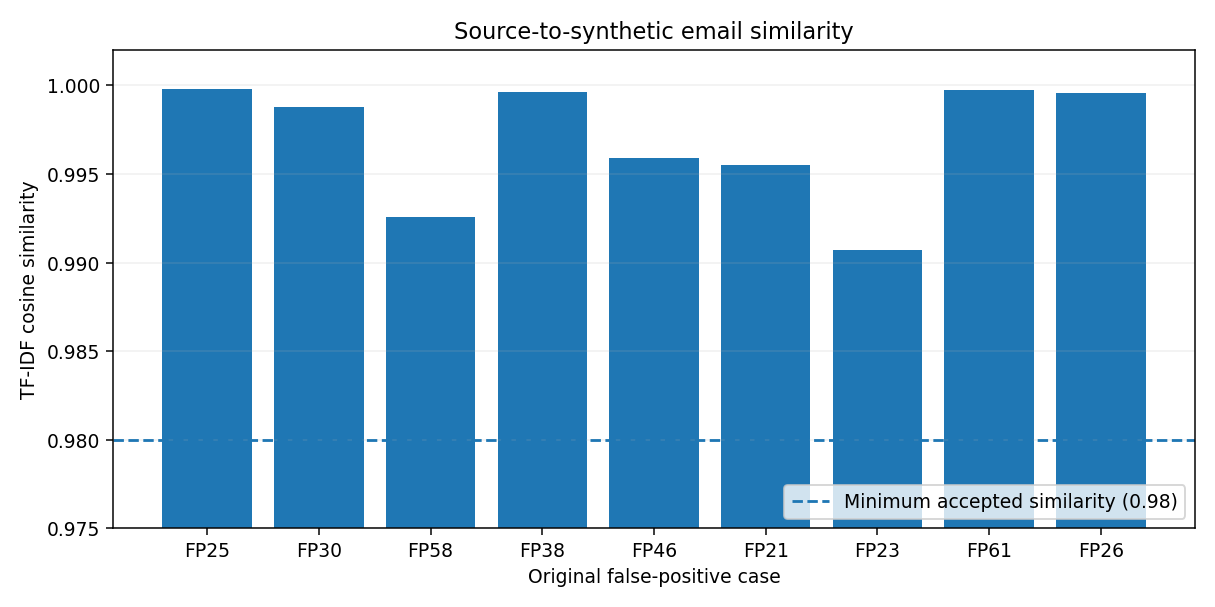

In [ ]:
# Figure 1 — Recorded similarity of the nine synthetic emails to their source emails.
# Values reproduce the original generation-stage results in Table 2.
import matplotlib.pyplot as plt
case_ids = ['FP25', 'FP30', 'FP58', 'FP38', 'FP46', 'FP21', 'FP23', 'FP61', 'FP26']
cosine_similarities = [0.99982029, 0.99877162, 0.99259114, 0.99965143, 0.99588916, 0.99551947, 0.99072639, 0.99974221, 0.99956062]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(case_ids, cosine_similarities)
ax.axhline(0.98, linestyle="--", linewidth=1.5, label="Minimum accepted similarity (0.98)")
ax.set_ylim(0.975, 1.002)
ax.set_xlabel("Original false-positive case")
ax.set_ylabel("TF-IDF cosine similarity")
ax.set_title("Source-to-synthetic email similarity")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


**Figure 1. TF-IDF cosine similarity between each synthetic email and its source email.** All nine recorded values exceed the 0.98 acceptance threshold. The plot is included as a saved notebook output so it is visible on GitHub without executing the code. The narrow vertical range highlights the small differences among values near 1.0.


**Table 2. Recorded synthetic-email generation results**

| Source case | Removed term | Words preserved | TF-IDF cosine similarity |
|---|---|---:|---:|
| FP25 | http | 99.68% | 0.99982029 |
| FP30 | www | 99.40% | 0.99877162 |
| FP58 | http | 98.15% | 0.99259114 |
| FP38 | just | 99.71% | 0.99965143 |
| FP46 | html | 98.51% | 0.99588916 |
| FP21 | work | 98.65% | 0.99551947 |
| FP23 | help | 99.35% | 0.99072639 |
| FP61 | new | 99.77% | 0.99974221 |
| FP26 | new | 99.69% | 0.99956062 |

*Source: Original synthetic-generation results. All nine variants preserved the selected counterfactual features. The recorded mean cosine similarity was 0.99691915.*


## 5. Validating the synthetic candidates

The original validation checked the intended legitimate label, controlled text variation, source similarity, preservation of counterfactual features, TF-IDF compatibility, and duplicate conditions. The locked baseline's predictions were also recorded to show whether the new candidates remained difficult for the original model.

All **nine candidates passed the recorded quality checks** and were approved for the later retraining experiment. The baseline classified all nine as phishing. Approval under these programmed checks does not independently establish the semantic legitimacy of every email; the assigned labels follow the source cases.


In [ ]:
# =========================================================================================================
# RANDOM FOREST
# STEP 13F: SYNTHETIC-DATA QUALITY AND LABEL VALIDATION
# SOURCE-SIMILARITY + COUNTERFACTUAL-PATTERN + MODEL-RESPONSE VERIFICATION
# =========================================================================================================
#
# PURPOSE
# -------
# Strictly validate the 9 counterfactual-guided synthetic legitimate
# emails produced in Step 13E before they are allowed to proceed
# to training augmentation.
#
#
# VALIDATION CHECKS
# -----------------
#
# 1. Label verification
#       Synthetic label must remain:
#
#           0 = Legitimate
#
# 2. Text integrity
#       - text must not be empty
#       - text must satisfy the original minimum cleaned length
#
# 3. Controlled variation
#       - synthetic email must differ from its source
#       - modification count must remain small
#
# 4. Source-context preservation
#       - word preservation must remain high
#       - TF-IDF cosine similarity must be >= 0.98
#
# 5. Counterfactual-pattern preservation
#       - every verified counterfactual feature must remain present
#
# 6. Preprocessing compatibility
#       - synthetic text must survive the same preprocessing rules
#       - locked TF-IDF vectorizer must transform it successfully
#
# 7. Duplicate validation
#       - synthetic candidates must not duplicate each other
#       - synthetic candidate must not be identical to its source
#
# 8. Locked-model response
#       - record Random Forest prediction and phishing probability
#       - this is diagnostic only
#
#
# APPROVAL RULE
# -------------
#
# A candidate is approved only when all DATA-QUALITY conditions pass.
#
# Locked-model prediction is recorded separately and is NOT used
# as the synthetic label.
#
#
# NO training augmentation occurs in this step.
# NO Random Forest retraining occurs in this step.
#
# =========================================================================================================


# =========================================================================================================
# 1. IMPORTS
# =========================================================================================================

import os
import re
import json
import hashlib
import numpy as np
import pandas as pd

from sklearn.metrics.pairwise import cosine_similarity


print("=" * 150)
print("RANDOM FOREST STEP 13F")
print("SYNTHETIC-DATA QUALITY AND LABEL VALIDATION")
print("SOURCE-SIMILARITY + COUNTERFACTUAL-PATTERN + MODEL-RESPONSE VERIFICATION")
print("=" * 150)


# =========================================================================================================
# 2. FIXED VALIDATION CONFIGURATION
# =========================================================================================================

EXPECTED_CANDIDATES_13F = 9

EXPECTED_LABEL_13F = 0

MIN_CLEAN_LENGTH_13F = 20

MIN_TFIDF_SIMILARITY_13F = 0.98

MIN_WORD_PRESERVATION_13F = 95.0

MAX_NON_CF_MODIFICATIONS_13F = 2


PROJECT_ROOT_13F = str(RF_PROJECT_ROOT)


STEP13E_FOLDER_13F = os.path.join(
    PROJECT_ROOT_13F,
    "Step13E_Counterfactual_Guided_Synthetic_Generation"
)


STEP13F_FOLDER = os.path.join(
    PROJECT_ROOT_13F,
    "Step13F_Synthetic_Data_Validation"
)


os.makedirs(
    STEP13F_FOLDER,
    exist_ok=True
)


# =========================================================================================================
# 3. RECOVER STEP 13E SYNTHETIC CANDIDATES
# =========================================================================================================

if "RF_STEP13E_SYNTHETIC_EMAILS" in globals():

    synthetic_candidates_13f = (
        RF_STEP13E_SYNTHETIC_EMAILS
        .copy()
    )

else:

    STEP13E_PATH_13F = os.path.join(
        STEP13E_FOLDER_13F,
        "Step13E_RF_Counterfactual_Guided_Synthetic_Legitimate_Emails.csv"
    )


    if not os.path.exists(
        STEP13E_PATH_13F
    ):

        raise RuntimeError(
            "\nStep 13E synthetic candidate file was not found.\n\n"
            "Run the accepted Random Forest Step 13E first."
        )


    synthetic_candidates_13f = pd.read_csv(
        STEP13E_PATH_13F
    )


# =========================================================================================================
# 4. VERIFY REQUIRED STEP 13E COLUMNS
# =========================================================================================================

required_columns_13f = [

    "Synthetic_ID",

    "Source_FP_Number",

    "Source_Test_Position",

    "Label",

    "Source_Phishing_Probability",

    "Minimal_CF_Feature_Count",

    "Counterfactual_Features",

    "Preserved_CF_Feature_Count",

    "Non_CF_Modifications",

    "Non_CF_Modification_Count",

    "Controlled_Variation_Created",

    "Original_Source_Text",

    "Synthetic_Text",

    "Word_Preservation_Percent",

    "TFIDF_Cosine_Similarity",

    "All_CF_Features_Preserved",

    "Generation_Success"
]


missing_columns_13f = [

    column_13f

    for column_13f in required_columns_13f

    if column_13f not in synthetic_candidates_13f.columns
]


if missing_columns_13f:

    raise RuntimeError(
        "\nStep 13E candidate table is missing required columns:\n"
        f"{missing_columns_13f}"
    )


assert len(
    synthetic_candidates_13f
) == EXPECTED_CANDIDATES_13F


print(
    "\nStep 13E synthetic candidates recovered:",
    len(
        synthetic_candidates_13f
    )
)


# =========================================================================================================
# 5. RECOVER LOCKED RANDOM FOREST
# =========================================================================================================

if "rf_baseline_model_locked" in globals():

    rf_model_13f = (
        rf_baseline_model_locked
    )

elif "rf_model" in globals():

    rf_model_13f = (
        rf_model
    )

else:

    raise RuntimeError(
        "Locked Random Forest model was not found."
    )


# =========================================================================================================
# 6. VERIFY LOCKED TF-IDF VECTORIZER
# =========================================================================================================

if "tfidf_vectorizer" not in globals():

    raise RuntimeError(
        "Locked TF-IDF vectorizer was not found."
    )


analyzer_13f = (
    tfidf_vectorizer.build_analyzer()
)


classes_13f = np.asarray(
    rf_model_13f.classes_
)


class1_positions_13f = np.where(
    classes_13f == 1
)[0]


assert len(
    class1_positions_13f
) == 1


class1_column_13f = int(
    class1_positions_13f[0]
)


# =========================================================================================================
# 7. HELPERS
# =========================================================================================================

def normalize_text_13f(
    text_13f
):

    return re.sub(
        r"\s+",
        " ",
        str(
            text_13f
        ).strip()
    )


def parse_cf_features_13f(
    feature_string_13f
):

    return [

        feature_13f.strip().lower()

        for feature_13f in str(
            feature_string_13f
        ).split("|")

        if feature_13f.strip()
    ]


def clean_email_text_13f(
    text_13f
):
    """
    Same cleaning procedure used in original Random Forest Step 2.
    """

    text_13f = str(
        text_13f
    ).lower()


    text_13f = re.sub(
        r"http\S+|www\S+",
        " ",
        text_13f
    )


    text_13f = re.sub(
        r"\S+@\S+",
        " ",
        text_13f
    )


    text_13f = re.sub(
        r"[^a-zA-Z0-9\s]",
        " ",
        text_13f
    )


    text_13f = re.sub(
        r"\s+",
        " ",
        text_13f
    ).strip()


    return text_13f


# =========================================================================================================
# 8. BASIC LABEL VALIDATION
# =========================================================================================================

synthetic_candidates_13f[
    "Label_Valid"
] = (

    synthetic_candidates_13f[
        "Label"
    ].astype(int)

    ==
    EXPECTED_LABEL_13F
)


# =========================================================================================================
# 9. TEXT INTEGRITY VALIDATION
# =========================================================================================================

synthetic_candidates_13f[
    "Synthetic_Text_Normalized"
] = (

    synthetic_candidates_13f[
        "Synthetic_Text"
    ]
    .astype(str)
    .apply(
        normalize_text_13f
    )
)


synthetic_candidates_13f[
    "Synthetic_Character_Count"
] = (

    synthetic_candidates_13f[
        "Synthetic_Text_Normalized"
    ]
    .str.len()
)


synthetic_candidates_13f[
    "Synthetic_Word_Count_13F"
] = (

    synthetic_candidates_13f[
        "Synthetic_Text_Normalized"
    ]
    .str.split()
    .str.len()
)


synthetic_candidates_13f[
    "Nonempty_Text"
] = (

    synthetic_candidates_13f[
        "Synthetic_Character_Count"
    ]
    >
    0
)


synthetic_candidates_13f[
    "Minimum_Length_Passed"
] = (

    synthetic_candidates_13f[
        "Synthetic_Character_Count"
    ]

    >=

    MIN_CLEAN_LENGTH_13F
)


# =========================================================================================================
# 10. CONTROLLED VARIATION VALIDATION
# =========================================================================================================

synthetic_candidates_13f[
    "Different_From_Source"
] = (

    synthetic_candidates_13f[
        "Synthetic_Text_Normalized"
    ]

    !=

    synthetic_candidates_13f[
        "Original_Source_Text"
    ]
    .astype(str)
    .apply(
        normalize_text_13f
    )
)


synthetic_candidates_13f[
    "Modification_Count_Valid"
] = (

    synthetic_candidates_13f[
        "Non_CF_Modification_Count"
    ].astype(int)

    <=

    MAX_NON_CF_MODIFICATIONS_13F
)


synthetic_candidates_13f[
    "Controlled_Variation_Valid"
] = (

    synthetic_candidates_13f[
        "Controlled_Variation_Created"
    ].astype(bool)

    &

    synthetic_candidates_13f[
        "Different_From_Source"
    ]

    &

    synthetic_candidates_13f[
        "Modification_Count_Valid"
    ]
)


# =========================================================================================================
# 11. RECOMPUTE WORD PRESERVATION
# =========================================================================================================

original_word_counts_13f = (

    synthetic_candidates_13f[
        "Original_Source_Text"
    ]
    .astype(str)
    .str.split()
    .str.len()
)


synthetic_word_counts_13f = (

    synthetic_candidates_13f[
        "Synthetic_Text_Normalized"
    ]
    .str.split()
    .str.len()
)


recomputed_word_preservation_13f = (

    synthetic_word_counts_13f

    /

    original_word_counts_13f

    *

    100
)


synthetic_candidates_13f[
    "Recomputed_Word_Preservation_Percent"
] = (
    recomputed_word_preservation_13f
)


synthetic_candidates_13f[
    "Word_Preservation_Passed"
] = (

    synthetic_candidates_13f[
        "Recomputed_Word_Preservation_Percent"
    ]

    >=

    MIN_WORD_PRESERVATION_13F
)


# =========================================================================================================
# 12. RECOMPUTE TF-IDF COSINE SIMILARITY
# =========================================================================================================

original_tfidf_13f = (
    tfidf_vectorizer.transform(
        synthetic_candidates_13f[
            "Original_Source_Text"
        ]
    )
)


synthetic_tfidf_13f = (
    tfidf_vectorizer.transform(
        synthetic_candidates_13f[
            "Synthetic_Text_Normalized"
        ]
    )
)


recomputed_similarity_13f = []


for row_index_13f in range(
    EXPECTED_CANDIDATES_13F
):


    similarity_13f = float(

        cosine_similarity(

            original_tfidf_13f[
                row_index_13f
            ],

            synthetic_tfidf_13f[
                row_index_13f
            ]

        )[0, 0]
    )


    recomputed_similarity_13f.append(
        similarity_13f
    )


synthetic_candidates_13f[
    "Recomputed_TFIDF_Cosine_Similarity"
] = (
    recomputed_similarity_13f
)


synthetic_candidates_13f[
    "TFIDF_Similarity_Passed"
] = (

    synthetic_candidates_13f[
        "Recomputed_TFIDF_Cosine_Similarity"
    ]

    >=

    MIN_TFIDF_SIMILARITY_13F
)


# =========================================================================================================
# 13. VERIFY STEP 13E SIMILARITY REPRODUCES
# =========================================================================================================

similarity_difference_13f = np.abs(

    synthetic_candidates_13f[
        "Recomputed_TFIDF_Cosine_Similarity"
    ].to_numpy()

    -

    synthetic_candidates_13f[
        "TFIDF_Cosine_Similarity"
    ].astype(float).to_numpy()
)


synthetic_candidates_13f[
    "Step13E_Similarity_Reproduced"
] = (

    similarity_difference_13f

    <=

    1e-12
)


# =========================================================================================================
# 14. COUNTERFACTUAL FEATURE-PATTERN PRESERVATION
# =========================================================================================================

preserved_feature_counts_13f = []

missing_cf_features_13f = []

all_cf_preserved_13f = []


for row_13f in (
    synthetic_candidates_13f.itertuples()
):


    cf_features_13f = (
        parse_cf_features_13f(
            row_13f.Counterfactual_Features
        )
    )


    analyzed_features_13f = set(

        analyzer_13f(
            row_13f.Synthetic_Text_Normalized
        )
    )


    preserved_13f = [

        feature_13f

        for feature_13f in cf_features_13f

        if feature_13f
        in analyzed_features_13f
    ]


    missing_13f = [

        feature_13f

        for feature_13f in cf_features_13f

        if feature_13f
        not in analyzed_features_13f
    ]


    preserved_feature_counts_13f.append(
        len(
            preserved_13f
        )
    )


    missing_cf_features_13f.append(
        " | ".join(
            missing_13f
        )
    )


    all_cf_preserved_13f.append(
        len(
            missing_13f
        )
        ==
        0
    )


synthetic_candidates_13f[
    "Validated_CF_Features_Preserved"
] = (
    preserved_feature_counts_13f
)


synthetic_candidates_13f[
    "Validated_Missing_CF_Features"
] = (
    missing_cf_features_13f
)


synthetic_candidates_13f[
    "CF_Pattern_Preservation_Passed"
] = (
    all_cf_preserved_13f
)


# =========================================================================================================
# 15. VERIFY EXPECTED COUNTERFACTUAL FEATURE COUNTS
# =========================================================================================================

synthetic_candidates_13f[
    "CF_Feature_Count_Valid"
] = (

    synthetic_candidates_13f[
        "Validated_CF_Features_Preserved"
    ]

    ==

    synthetic_candidates_13f[
        "Minimal_CF_Feature_Count"
    ].astype(int)
)


# =========================================================================================================
# 16. PREPROCESSING COMPATIBILITY
# =========================================================================================================
#
# Synthetic text is passed through the exact Step 2 cleaning function.
#
# Because Step 13E works on already-cleaned source text,
# the cleaned result should remain stable.
#
# =========================================================================================================

recleaned_texts_13f = (

    synthetic_candidates_13f[
        "Synthetic_Text_Normalized"
    ]
    .apply(
        clean_email_text_13f
    )
)


synthetic_candidates_13f[
    "Recleaned_Text"
] = (
    recleaned_texts_13f
)


synthetic_candidates_13f[
    "Preprocessing_Stable"
] = (

    synthetic_candidates_13f[
        "Recleaned_Text"
    ]

    ==

    synthetic_candidates_13f[
        "Synthetic_Text_Normalized"
    ]
)


# Verify TF-IDF transformation succeeded and produced correct dimensions.

assert synthetic_tfidf_13f.shape == (
    EXPECTED_CANDIDATES_13F,
    len(
        tfidf_vectorizer
        .get_feature_names_out()
    )
)


synthetic_candidates_13f[
    "TFIDF_Transformation_Passed"
] = True


# =========================================================================================================
# 17. EXACT DUPLICATE CHECK AMONG SYNTHETIC CANDIDATES
# =========================================================================================================

synthetic_candidates_13f[
    "Duplicate_Among_Synthetic"
] = (

    synthetic_candidates_13f[
        "Synthetic_Text_Normalized"
    ]
    .duplicated(
        keep=False
    )
)


synthetic_candidates_13f[
    "Synthetic_Unique"
] = (

    ~synthetic_candidates_13f[
        "Duplicate_Among_Synthetic"
    ]
)


# =========================================================================================================
# 18. DUPLICATE CHECK AGAINST SOURCE EMAILS
# =========================================================================================================

synthetic_candidates_13f[
    "Identical_To_Source"
] = (

    synthetic_candidates_13f[
        "Synthetic_Text_Normalized"
    ]

    ==

    synthetic_candidates_13f[
        "Original_Source_Text"
    ]
    .astype(str)
    .apply(
        normalize_text_13f
    )
)


synthetic_candidates_13f[
    "Source_Difference_Passed"
] = (

    ~synthetic_candidates_13f[
        "Identical_To_Source"
    ]
)


# =========================================================================================================
# 19. OPTIONAL DUPLICATE CHECK AGAINST ORIGINAL TRAINING TEXT
# =========================================================================================================
#
# If X_train is available from Step 13D-R, verify that the
# synthetic candidate is not already an exact training example.
#
# =========================================================================================================

if "X_train" in globals():

    original_training_texts_13f = set(

        pd.Series(
            X_train
        )
        .astype(str)
        .apply(
            normalize_text_13f
        )
        .tolist()
    )


    synthetic_candidates_13f[
        "Exact_Duplicate_In_Training"
    ] = [

        synthetic_text_13f
        in
        original_training_texts_13f

        for synthetic_text_13f
        in synthetic_candidates_13f[
            "Synthetic_Text_Normalized"
        ]
    ]


else:

    synthetic_candidates_13f[
        "Exact_Duplicate_In_Training"
    ] = False


synthetic_candidates_13f[
    "Training_Duplicate_Check_Passed"
] = (

    ~synthetic_candidates_13f[
        "Exact_Duplicate_In_Training"
    ]
)


# =========================================================================================================
# 20. LOCKED RANDOM FOREST RESPONSE
# =========================================================================================================
#
# Diagnostic only.
#
# Synthetic examples remain labelled Legitimate (0).
#
# =========================================================================================================

locked_predictions_13f = (

    rf_model_13f.predict(
        synthetic_tfidf_13f
    )

    .astype(int)
)


locked_probabilities_13f = (

    rf_model_13f.predict_proba(
        synthetic_tfidf_13f
    )[
        :,
        class1_column_13f
    ]
)


synthetic_candidates_13f[
    "Locked_RF_Prediction"
] = (
    locked_predictions_13f
)


synthetic_candidates_13f[
    "Locked_RF_Phishing_Probability"
] = (
    locked_probabilities_13f
)


synthetic_candidates_13f[
    "Locked_RF_Predicts_Phishing"
] = (

    synthetic_candidates_13f[
        "Locked_RF_Prediction"
    ]

    ==
    1
)


# =========================================================================================================
# 21. CHANGE FROM SOURCE MODEL RESPONSE
# =========================================================================================================

synthetic_candidates_13f[
    "Probability_Change_From_Source"
] = (

    synthetic_candidates_13f[
        "Locked_RF_Phishing_Probability"
    ]

    -

    synthetic_candidates_13f[
        "Source_Phishing_Probability"
    ].astype(float)
)


# =========================================================================================================
# 22. FINAL DATA-QUALITY APPROVAL
# =========================================================================================================
#
# Model prediction is NOT part of the approval condition.
#
# Approval concerns:
#
#   label
#   text integrity
#   controlled variation
#   similarity
#   context preservation
#   CF-pattern preservation
#   preprocessing
#   uniqueness
#
# =========================================================================================================

synthetic_candidates_13f[
    "Approved_For_Training"
] = (

    synthetic_candidates_13f[
        "Label_Valid"
    ]

    &

    synthetic_candidates_13f[
        "Nonempty_Text"
    ]

    &

    synthetic_candidates_13f[
        "Minimum_Length_Passed"
    ]

    &

    synthetic_candidates_13f[
        "Controlled_Variation_Valid"
    ]

    &

    synthetic_candidates_13f[
        "Word_Preservation_Passed"
    ]

    &

    synthetic_candidates_13f[
        "TFIDF_Similarity_Passed"
    ]

    &

    synthetic_candidates_13f[
        "Step13E_Similarity_Reproduced"
    ]

    &

    synthetic_candidates_13f[
        "CF_Pattern_Preservation_Passed"
    ]

    &

    synthetic_candidates_13f[
        "CF_Feature_Count_Valid"
    ]

    &

    synthetic_candidates_13f[
        "Preprocessing_Stable"
    ]

    &

    synthetic_candidates_13f[
        "TFIDF_Transformation_Passed"
    ]

    &

    synthetic_candidates_13f[
        "Synthetic_Unique"
    ]

    &

    synthetic_candidates_13f[
        "Source_Difference_Passed"
    ]

    &

    synthetic_candidates_13f[
        "Training_Duplicate_Check_Passed"
    ]
)


# =========================================================================================================
# 23. APPROVED / REJECTED SUBSETS
# =========================================================================================================

approved_candidates_13f = (

    synthetic_candidates_13f[
        synthetic_candidates_13f[
            "Approved_For_Training"
        ]
    ]

    .copy()

    .reset_index(drop=True)
)


rejected_candidates_13f = (

    synthetic_candidates_13f[
        ~synthetic_candidates_13f[
            "Approved_For_Training"
        ]
    ]

    .copy()

    .reset_index(drop=True)
)


# =========================================================================================================
# 24. MAIN VALIDATION TABLE
# =========================================================================================================

print(
    "\n" + "=" * 150
)

print(
    "STEP 13F SYNTHETIC-DATA VALIDATION RESULTS"
)

print(
    "=" * 150
)


display(

    synthetic_candidates_13f[
        [
            "Synthetic_ID",

            "Source_FP_Number",

            "Label_Valid",

            "Controlled_Variation_Valid",

            "Recomputed_Word_Preservation_Percent",

            "Recomputed_TFIDF_Cosine_Similarity",

            "CF_Pattern_Preservation_Passed",

            "Preprocessing_Stable",

            "Synthetic_Unique",

            "Training_Duplicate_Check_Passed",

            "Locked_RF_Prediction",

            "Locked_RF_Phishing_Probability",

            "Probability_Change_From_Source",

            "Approved_For_Training"
        ]
    ]

    .style.format({

        "Recomputed_Word_Preservation_Percent":
            "{:.2f}%",

        "Recomputed_TFIDF_Cosine_Similarity":
            "{:.8f}",

        "Locked_RF_Phishing_Probability":
            "{:.8f}",

        "Probability_Change_From_Source":
            "{:+.8f}"
    })
)


# =========================================================================================================
# 25. VALIDATION SUMMARY
# =========================================================================================================

print(
    "\n" + "=" * 150
)

print(
    "SYNTHETIC-DATA QUALITY SUMMARY"
)

print(
    "=" * 150
)


print(
    "\nTotal candidates:",
    EXPECTED_CANDIDATES_13F
)


print(
    "Valid legitimate labels:",
    int(
        synthetic_candidates_13f[
            "Label_Valid"
        ].sum()
    ),
    "/",
    EXPECTED_CANDIDATES_13F
)


print(
    "Controlled variation passed:",
    int(
        synthetic_candidates_13f[
            "Controlled_Variation_Valid"
        ].sum()
    ),
    "/",
    EXPECTED_CANDIDATES_13F
)


print(
    "Word preservation >=",
    f"{MIN_WORD_PRESERVATION_13F:.0f}%:",
    int(
        synthetic_candidates_13f[
            "Word_Preservation_Passed"
        ].sum()
    ),
    "/",
    EXPECTED_CANDIDATES_13F
)


print(
    "TF-IDF similarity >=",
    MIN_TFIDF_SIMILARITY_13F,
    ":",
    int(
        synthetic_candidates_13f[
            "TFIDF_Similarity_Passed"
        ].sum()
    ),
    "/",
    EXPECTED_CANDIDATES_13F
)


print(
    "Counterfactual patterns preserved:",
    int(
        synthetic_candidates_13f[
            "CF_Pattern_Preservation_Passed"
        ].sum()
    ),
    "/",
    EXPECTED_CANDIDATES_13F
)


print(
    "Preprocessing stable:",
    int(
        synthetic_candidates_13f[
            "Preprocessing_Stable"
        ].sum()
    ),
    "/",
    EXPECTED_CANDIDATES_13F
)


print(
    "Synthetic candidates unique:",
    int(
        synthetic_candidates_13f[
            "Synthetic_Unique"
        ].sum()
    ),
    "/",
    EXPECTED_CANDIDATES_13F
)


print(
    "Exact training duplicates absent:",
    int(
        synthetic_candidates_13f[
            "Training_Duplicate_Check_Passed"
        ].sum()
    ),
    "/",
    EXPECTED_CANDIDATES_13F
)


print(
    "\nApproved for training:",
    len(
        approved_candidates_13f
    ),
    "/",
    EXPECTED_CANDIDATES_13F
)


print(
    "Rejected:",
    len(
        rejected_candidates_13f
    )
)


# =========================================================================================================
# 26. LOCKED MODEL RESPONSE SUMMARY
# =========================================================================================================

print(
    "\n" + "=" * 150
)

print(
    "LOCKED RANDOM FOREST RESPONSE TO SYNTHETIC LEGITIMATE EMAILS"
)

print(
    "=" * 150
)


print(
    "\nPredicted Legitimate (0):",
    int(
        np.sum(
            locked_predictions_13f
            ==
            0
        )
    )
)


print(
    "Predicted Phishing (1):",
    int(
        np.sum(
            locked_predictions_13f
            ==
            1
        )
    )
)


print(
    "\nMean phishing probability:",
    float(
        np.mean(
            locked_probabilities_13f
        )
    )
)


print(
    "Minimum phishing probability:",
    float(
        np.min(
            locked_probabilities_13f
        )
    )
)


print(
    "Maximum phishing probability:",
    float(
        np.max(
            locked_probabilities_13f
        )
    )
)


# =========================================================================================================
# 27. DISPLAY APPROVED CANDIDATES
# =========================================================================================================

print(
    "\n" + "=" * 150
)

print(
    "APPROVED SYNTHETIC LEGITIMATE EMAILS"
)

print(
    "=" * 150
)


if len(
    approved_candidates_13f
) > 0:


    display(

        approved_candidates_13f[
            [
                "Synthetic_ID",

                "Source_FP_Number",

                "Counterfactual_Features",

                "Non_CF_Modifications",

                "Recomputed_Word_Preservation_Percent",

                "Recomputed_TFIDF_Cosine_Similarity",

                "Locked_RF_Prediction",

                "Locked_RF_Phishing_Probability"
            ]
        ]

        .style.format({

            "Recomputed_Word_Preservation_Percent":
                "{:.2f}%",

            "Recomputed_TFIDF_Cosine_Similarity":
                "{:.8f}",

            "Locked_RF_Phishing_Probability":
                "{:.8f}"
        })
    )


else:

    print(
        "\nNo candidate passed all validation rules."
    )


# =========================================================================================================
# 28. DISPLAY REJECTED CANDIDATES
# =========================================================================================================

if len(
    rejected_candidates_13f
) > 0:


    print(
        "\n" + "=" * 150
    )

    print(
        "REJECTED SYNTHETIC CANDIDATES"
    )

    print(
        "=" * 150
    )


    display(

        rejected_candidates_13f[
            [
                "Synthetic_ID",

                "Source_FP_Number",

                "Label_Valid",

                "Controlled_Variation_Valid",

                "Word_Preservation_Passed",

                "TFIDF_Similarity_Passed",

                "CF_Pattern_Preservation_Passed",

                "Preprocessing_Stable",

                "Synthetic_Unique",

                "Training_Duplicate_Check_Passed"
            ]
        ]
    )


# =========================================================================================================
# 29. SAVE FULL VALIDATION RESULTS
# =========================================================================================================

VALIDATION_PATH_13F = os.path.join(

    STEP13F_FOLDER,

    "Step13F_RF_Synthetic_Data_Validation.csv"
)


synthetic_candidates_13f.to_csv(
    VALIDATION_PATH_13F,
    index=False
)


# =========================================================================================================
# 30. SAVE APPROVED CANDIDATES
# =========================================================================================================

APPROVED_PATH_13F = os.path.join(

    STEP13F_FOLDER,

    "Step13F_RF_Approved_Synthetic_Legitimate_Emails.csv"
)


approved_candidates_13f.to_csv(
    APPROVED_PATH_13F,
    index=False
)


# =========================================================================================================
# 31. SAVE REJECTED CANDIDATES
# =========================================================================================================

REJECTED_PATH_13F = os.path.join(

    STEP13F_FOLDER,

    "Step13F_RF_Rejected_Synthetic_Candidates.csv"
)


rejected_candidates_13f.to_csv(
    REJECTED_PATH_13F,
    index=False
)


# =========================================================================================================
# 32. HASH APPROVED DATA
# =========================================================================================================

def sha256_file_13f(
    path_13f
):

    hasher_13f = hashlib.sha256()


    with open(
        path_13f,
        "rb"
    ) as file_13f:


        for block_13f in iter(

            lambda:
                file_13f.read(
                    1024 * 1024
                ),

            b""
        ):


            hasher_13f.update(
                block_13f
            )


    return hasher_13f.hexdigest()


approved_hash_13f = (
    sha256_file_13f(
        APPROVED_PATH_13F
    )
)


print(
    "\nApproved synthetic dataset SHA-256:"
)

print(
    approved_hash_13f
)


# =========================================================================================================
# 33. SAVE CONFIGURATION
# =========================================================================================================

CONFIG_PATH_13F = os.path.join(
    STEP13F_FOLDER,
    "Step13F_Config.json"
)


config_13f = {

    "step":
        "13F",

    "method":
        (
            "Strict synthetic-data quality, label, similarity, "
            "counterfactual-pattern and locked-model-response validation"
        ),

    "total_candidates":
        EXPECTED_CANDIDATES_13F,

    "approved_candidates":
        int(
            len(
                approved_candidates_13f
            )
        ),

    "rejected_candidates":
        int(
            len(
                rejected_candidates_13f
            )
        ),

    "minimum_tfidf_similarity":
        MIN_TFIDF_SIMILARITY_13F,

    "minimum_word_preservation_percent":
        MIN_WORD_PRESERVATION_13F,

    "maximum_non_cf_modifications":
        MAX_NON_CF_MODIFICATIONS_13F,

    "locked_model_predicted_phishing":
        int(
            np.sum(
                locked_predictions_13f
                ==
                1
            )
        ),

    "locked_model_predicted_legitimate":
        int(
            np.sum(
                locked_predictions_13f
                ==
                0
            )
        ),

    "approved_dataset_hash":
        approved_hash_13f,

    "quality_validation_completed":
        True,

    "training_augmentation":
        False,

    "model_retrained":
        False,

    "locked_model_modified":
        False
}


with open(
    CONFIG_PATH_13F,
    "w"
) as file_13f:

    json.dump(
        config_13f,
        file_13f,
        indent=4
    )


# =========================================================================================================
# 34. CREATE OBJECTS FOR STEP 13G
# =========================================================================================================

RF_STEP13F_VALIDATION_RESULTS = (
    synthetic_candidates_13f.copy()
)


RF_STEP13F_APPROVED_SYNTHETIC = (
    approved_candidates_13f.copy()
)


RF_STEP13F_REJECTED_SYNTHETIC = (
    rejected_candidates_13f.copy()
)


RF_STEP13F_APPROVED_HASH = (
    approved_hash_13f
)


RF_STEP13F_APPROVED_COUNT = int(
    len(
        approved_candidates_13f
    )
)


# =========================================================================================================
# 35. FINAL CONFIRMATION
# =========================================================================================================

print(
    "\n" + "=" * 150
)

print(
    "RANDOM FOREST STEP 13F COMPLETE"
)

print(
    "=" * 150
)


print(
    "\nSynthetic candidates evaluated:",
    EXPECTED_CANDIDATES_13F
)


print(
    "Approved for training:",
    len(
        approved_candidates_13f
    )
)


print(
    "Rejected:",
    len(
        rejected_candidates_13f
    )
)


print(
    "\nApproved dataset hash:"
)

print(
    approved_hash_13f
)


print(
    "\nNo training augmentation performed."
)


print(
    "No TF-IDF fitting/refitting performed."
)


print(
    "No Random Forest retraining performed."
)


print(
    "Locked Random Forest remained unchanged."
)


print(
    "\nNEXT:"
)


print(
    "Step 13G will use ONLY the approved synthetic legitimate "
    "emails for controlled training augmentation and Random Forest retraining."
)

**Table 3. Original validation summary**

| Validation result | Recorded value |
|---|---:|
| Synthetic candidates evaluated | 9 |
| Candidates approved | 9 |
| Candidates rejected | 0 |
| Candidates preserving all counterfactual features | 9 |
| Candidates meeting the similarity threshold | 9 |
| Candidates predicted as phishing by the locked baseline | 9 |
| Mean baseline phishing probability | 0.57997290 |

*Source: Original synthetic-data validation output. This table summarizes the recorded checks; the code above contains the case-level verification.*


## 6. Discussion and conclusion

The text-recovery checks connected the counterfactual analysis to the exact emails used in the locked Random Forest baseline. The reconstruction stage showed that the nine verified feature-space cases could be traced to their original text, but it did not establish that simple word removal would reproduce the feature-space predictions.

The generation stage then created nine highly similar legitimate-email candidates while retaining the counterfactual features. All nine passed the original validation criteria and remained classified as phishing by the baseline model. This provides the original experimental basis for testing whether additional legitimate examples can reduce false positives during the subsequent model-improvement stage.

No Random Forest retraining or final performance comparison is performed in RF 05. The next notebook addresses those results separately.
